# Single-Cell RNA-seq Analysis of Breast Cancer

This project analyzes single-cell RNA-seq data from six biological samples—three healthy mammary tissue samples and three ER-positive breast tumors—to characterize cellular heterogeneity and explore sample-level disease classification.

The workflow integrates quality control, normalization, dimensionality reduction, batch-aware clustering, marker-based cell-type annotation, differential expression, and machine-learning evaluation. Intermediate objects and analysis outputs are saved at each stage.

## Contents

- [Step 1 — Dataset Loading and Sample Metadata](#step-1)
- [Step 2 — Quality Control](#step-2)
- [Step 3 — Normalization and Feature Selection](#step-3)
- [Step 4 — Dimensionality Reduction and Initial Clustering](#step-4)
- [Step 5 — Batch-Aware Clustering](#step-5)
- [Step 6 — Cell-Type Annotation and Differential Expression](#step-6)
- [Step 7 — Sample-Level Feature Engineering and Model Training](#step-7)
- [Step 8 — Model Evaluation](#step-8)
- [Step 9 — Model Comparison and Feature Interpretation](#step-9)
- [Step 10 — Results Synthesis](#step-10)

In [ ]:
# Install the dependencies required for the analysis.
# Run once per Google Colab runtime, if needed.
%pip -q install "scanpy[leiden]" scikit-misc bbknn

<a id="step-1"></a>
## Step 1 — Dataset Loading and Sample Metadata

The GSE161529 count matrices are loaded using a shared gene-feature annotation and combined into a single AnnData object. Sample identifiers, patient identifiers, and condition labels are retained throughout the analysis. The dataset comprises three healthy samples and three ER-positive breast tumor samples.

In [ ]:
# Mount Google Drive and configure the project environment.
from google.colab import drive
drive.mount("/content/drive")

import gzip
import os
import re
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.io import mmread

PROJECT_DIR = Path("/content/drive/MyDrive/bioinformatics final project")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR
BASE_DIR = str(DATA_DIR)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Dataset directory not found: {DATA_DIR}")

os.listdir(BASE_DIR)[:50]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


['GSM4909297_ER-MH0125-matrix.mtx.gz',
 'GSM4909254_N-PM0019-Total-barcodes.tsv.gz',
 'GSM4909253_N-PM0092-Total-matrix.mtx.gz',
 'GSM4909298_ER-PM0360-barcodes.tsv.gz',
 'GSE161529_features.tsv.gz',
 'GSM4909253_N-PM0092-Total-barcodes.tsv.gz',
 'GSM4909296_ER-MH0001-matrix.mtx.gz',
 'GSM4909298_ER-PM0360-matrix.mtx.gz',
 'GSM4909265_N-PM0233-Total-barcodes.tsv.gz',
 'GSM4909296_ER-MH0001-barcodes.tsv.gz',
 'GSM4909297_ER-MH0125-barcodes.tsv.gz',
 'GSM4909254_N-PM0019-Total-matrix.mtx.gz',
 'GSM4909265_N-PM0233-Total-matrix.mtx.gz']

In [ ]:
# Load the shared gene-feature annotation for GSE161529.
features_path = DATA_DIR / "GSE161529_features.tsv.gz"

features = pd.read_csv(
    features_path,
    sep="\t",
    header=None,
    compression="gzip",
)

# Use the gene-symbol column when available.
symbol_col = 1 if features.shape[1] >= 2 else 0
gene_symbols = features.iloc[:, symbol_col].astype(str).to_numpy()

print("Features rows:", len(gene_symbols))
print("Example symbols:", gene_symbols[:10])

Features rows: 33538
Example symbols: ['MIR1302-2HG' 'FAM138A' 'OR4F5' 'AL627309.1' 'AL627309.3' 'AL627309.2'
 'AL627309.4' 'AL732372.1' 'OR4F29' 'AC114498.1']


In [ ]:
def load_sample_with_global_features(prefix, base_dir, gene_symbols):
    """Load one sample's count matrix and attach sample-level metadata."""
    matrix_path = os.path.join(base_dir, f"{prefix}-matrix.mtx.gz")
    barcodes_path = os.path.join(base_dir, f"{prefix}-barcodes.tsv.gz")

    # Read the gene-by-cell count matrix and cell barcodes.
    with gzip.open(matrix_path, "rb") as matrix_file:
        counts = mmread(matrix_file).tocsr()

    barcodes = (
        pd.read_csv(barcodes_path, header=None, sep="\t")[0]
        .astype(str)
        .to_numpy()
    )

    # Verify that the matrix matches its feature and barcode annotations.
    if counts.shape[0] != len(gene_symbols):
        raise ValueError(
            f"{prefix}: matrix contains {counts.shape[0]} genes, "
            f"but {len(gene_symbols)} feature annotations were provided."
        )

    if counts.shape[1] != len(barcodes):
        raise ValueError(
            f"{prefix}: matrix contains {counts.shape[1]} cells, "
            f"but {len(barcodes)} barcodes were provided."
        )

    # AnnData stores cells in rows and genes in columns.
    adata = ad.AnnData(X=counts.T)
    adata.obs_names = barcodes
    adata.var_names = gene_symbols
    adata.var_names_make_unique()

    # Attach sample and condition metadata.
    adata.obs["gsm"] = prefix.split("_")[0]
    adata.obs["sample_id"] = prefix

    if "_N-" in prefix or "_N_" in prefix:
        adata.obs["condition"] = "healthy"
    elif "_ER-" in prefix or "_ER_" in prefix:
        adata.obs["condition"] = "disease"
    else:
        adata.obs["condition"] = "unknown"

    patient_match = re.search(r"(PM|MH)\d{4}", prefix)
    adata.obs["patient_id"] = (
        patient_match.group(0) if patient_match else "unknown"
    )

    return adata

In [ ]:
# Load and merge the six biological samples.
sample_prefixes = [
    "GSM4909253_N-PM0092-Total",
    "GSM4909254_N-PM0019-Total",
    "GSM4909265_N-PM0233-Total",
    "GSM4909296_ER-MH0001",
    "GSM4909297_ER-MH0125",
    "GSM4909298_ER-PM0360",
]

adatas = [
    load_sample_with_global_features(prefix, BASE_DIR, gene_symbols)
    for prefix in sample_prefixes
]

# Make cell identifiers unique across samples.
for sample_adata in adatas:
    sample_id = str(sample_adata.obs["sample_id"].iloc[0])
    sample_adata.obs_names = [
        f"{sample_id}_{barcode}"
        for barcode in sample_adata.obs_names
    ]

# Combine samples while retaining sample identity in the metadata.
adata = ad.concat(
    adatas,
    join="outer",
    label="batch",
    keys=sample_prefixes,
)

adata.obs["batch"] = adata.obs["batch"].astype(str)

if not adata.obs_names.is_unique:
    raise ValueError("Cell identifiers are not unique after merging.")

# Save the merged raw-count object.
out_path = OUTPUT_DIR / "adata_step1_raw.h5ad"
adata.write_h5ad(out_path)

adata.var_names[:10].tolist(), (
    adata.var_names.str.upper().str.startswith("MT-").sum()
)

/tmp/ipython-input-127757152.py:15: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  adata = ad.concat(adatas, join="outer", label="batch", keys=[a.obs["sample_id"][0] for a in adatas])


(['MIR1302-2HG',
  'FAM138A',
  'OR4F5',
  'AL627309.1',
  'AL627309.3',
  'AL627309.2',
  'AL627309.4',
  'AL732372.1',
  'OR4F29',
  'AC114498.1'],
 np.int64(13))

In [ ]:
# Confirm that cell identifiers remain unique after merging.
assert adata.obs_names.is_unique, (
    "Duplicate cell identifiers detected after sample merging."
)

True

True

<a id="step-2"></a>
## Step 2 — Quality Control

Cell quality is assessed using total counts, detected genes, and mitochondrial-read percentage. Sample-specific lower thresholds, an upper gene-count threshold, and a 15% mitochondrial cutoff are applied. QC visualizations and per-sample retention summaries are used to examine filtering outcomes, and genes detected in fewer than three cells are removed.

In [ ]:
# Load the merged raw-count dataset.
import scanpy as sc
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/bioinformatics final project"
)

adata = sc.read_h5ad(
    PROJECT_DIR / "adata_step1_raw.h5ad"
)

print(adata)

display(
    pd.crosstab(
        adata.obs["condition"],
        adata.obs["sample_id"],
    )
)

AnnData object with n_obs × n_vars = 39101 × 33538
    obs: 'gsm', 'sample_id', 'condition', 'patient_id', 'batch'


sample_id,GSM4909253_N-PM0092-Total,GSM4909254_N-PM0019-Total,GSM4909265_N-PM0233-Total,GSM4909296_ER-MH0001,GSM4909297_ER-MH0125,GSM4909298_ER-PM0360
condition,,,,,,
disease,0,0,0,7375,7289,6676
healthy,4966,7130,5665,0,0,0


In [ ]:
# Calculate cell-level quality-control metrics.
adata.var_names_make_unique()
adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True,
)

# Summarize library size, detected genes, and mitochondrial fraction.
adata.obs[
    ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
].describe()

,total_counts,n_genes_by_counts,pct_counts_mt
count,39101.000000,39101.000000,39101.000000
mean,5771.245058,1370.272960,5.652600
std,9724.359801,1263.488376,9.416985
min,500.000000,23.000000,0.000000
25%,1041.000000,489.000000,1.923077
50%,2268.000000,874.000000,3.343465
75%,6303.000000,1837.000000,5.876866
max,159644.000000,9708.000000,94.100295


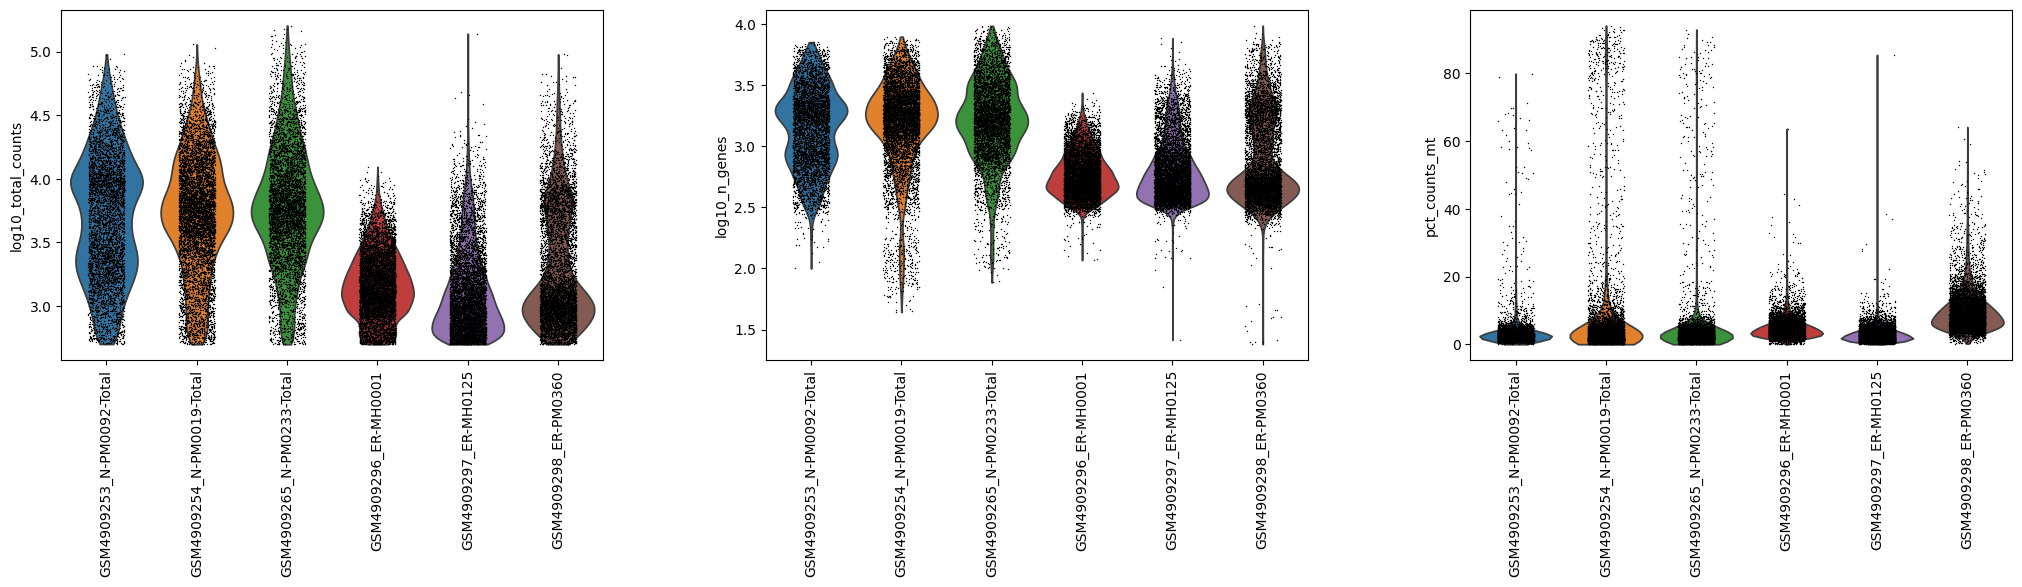

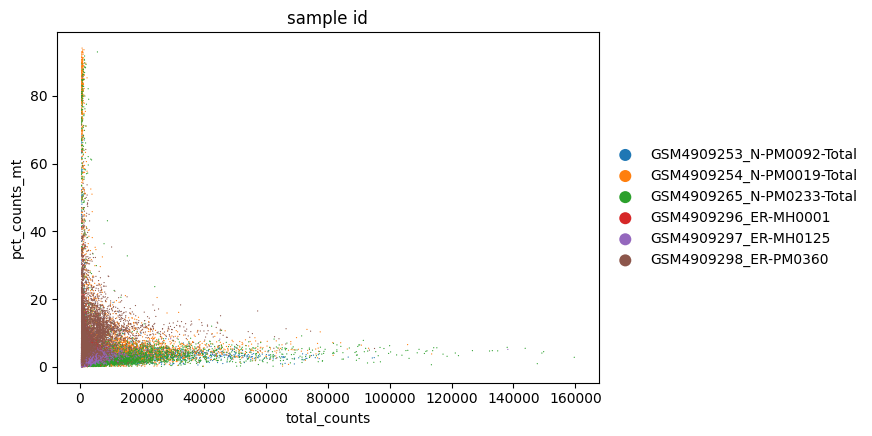

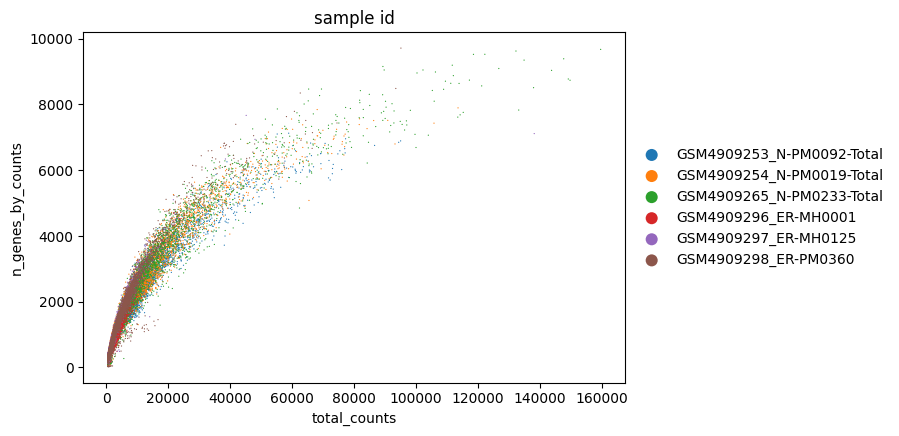

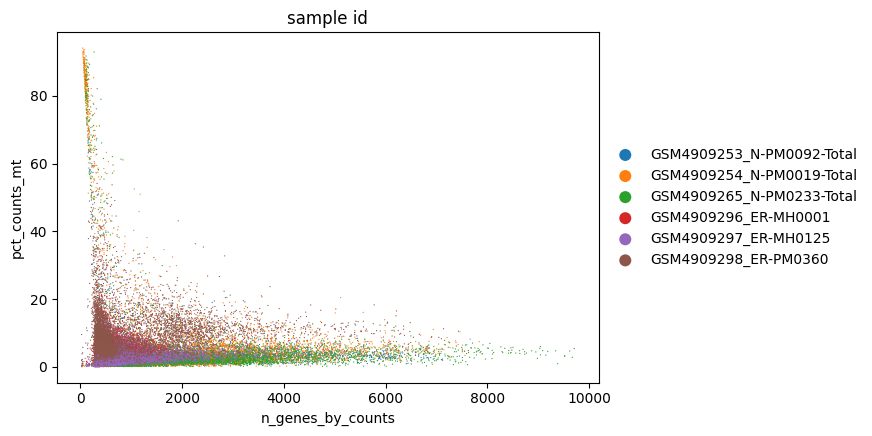

In [ ]:
# Prepare log-transformed QC metrics for visualization.
adata.obs["log10_total_counts"] = np.log10(
    adata.obs["total_counts"] + 1
)
adata.obs["log10_n_genes"] = np.log10(
    adata.obs["n_genes_by_counts"] + 1
)

# Compare QC distributions across biological samples.
sc.pl.violin(
    adata,
    ["log10_total_counts", "log10_n_genes", "pct_counts_mt"],
    groupby="sample_id",
    rotation=90,
    jitter=0.2,
    multi_panel=True,
)

# Examine relationships between library size, gene detection,
# and mitochondrial-read percentage.
sc.pl.scatter(
    adata, x="total_counts", y="pct_counts_mt", color="sample_id"
)
sc.pl.scatter(
    adata, x="total_counts", y="n_genes_by_counts", color="sample_id"
)
sc.pl.scatter(
    adata, x="n_genes_by_counts", y="pct_counts_mt", color="sample_id"
)

In [ ]:
# Define QC thresholds.
min_counts_floor = 500
min_genes_floor = 200
max_mt_pct = 15

q_low_counts = 0.01
q_low_genes = 0.01
q_high_genes = 0.995

# Estimate thresholds separately for each biological sample.
sample_qc = adata.obs.groupby("sample_id", observed=False)

thr_counts = sample_qc["total_counts"].quantile(q_low_counts)
thr_genes_low = sample_qc["n_genes_by_counts"].quantile(q_low_genes)
thr_genes_high = sample_qc["n_genes_by_counts"].quantile(q_high_genes)

# Apply minimum floors while retaining sample-specific upper bounds.
thr = pd.DataFrame({
    "min_counts": thr_counts.clip(lower=min_counts_floor),
    "min_genes": thr_genes_low.clip(lower=min_genes_floor),
    "max_genes": thr_genes_high,
})

thr.round(2)

/tmp/ipython-input-863152556.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  thr_counts = adata.obs.groupby("sample_id")["total_counts"].quantile(q_low_counts)
/tmp/ipython-input-863152556.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  thr_genes_low = adata.obs.groupby("sample_id")["n_genes_by_counts"].quantile(q_low_genes)
/tmp/ipython-input-863152556.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  thr_g

,min_counts,min_genes,max_genes
sample_id,,,
GSM4909253_N-PM0092-Total,545.00,285.00,6232.03
GSM4909254_N-PM0019-Total,550.00,200.00,6797.84
GSM4909265_N-PM0233-Total,553.64,200.00,8298.16
GSM4909296_ER-MH0001,515.74,287.00,1846.39
GSM4909297_ER-MH0125,506.00,291.00,3741.76
GSM4909298_ER-PM0360,515.00,245.75,6374.38


In [ ]:
# Retain cells meeting their sample-specific QC thresholds.
keep = np.ones(adata.n_obs, dtype=bool)
sample_ids = adata.obs["sample_id"].to_numpy()

for sample_id, thresholds in thr.iterrows():
    sample_mask = sample_ids == sample_id
    sample_obs = adata.obs.loc[sample_mask]

    keep[sample_mask] = (
        (sample_obs["total_counts"].to_numpy()
         >= thresholds["min_counts"])
        & (sample_obs["n_genes_by_counts"].to_numpy()
           >= thresholds["min_genes"])
        & (sample_obs["n_genes_by_counts"].to_numpy()
           <= thresholds["max_genes"])
        & (sample_obs["pct_counts_mt"].to_numpy() <= max_mt_pct)
    )

adata_qc = adata[keep].copy()

# Exclude genes detected in fewer than three retained cells.
sc.pp.filter_genes(adata_qc, min_cells=3)

# Summarize QC metrics after filtering.
adata_qc[
    :, :
].obs[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].describe()

,total_counts,n_genes_by_counts,pct_counts_mt
count,36490.000000,36490.000000,36490.000000
mean,5756.073089,1393.032584,4.033390
std,8933.848986,1225.210859,3.014254
min,506.000000,206.000000,0.000000
25%,1100.000000,512.000000,1.865041
50%,2396.500000,911.000000,3.167025
75%,6504.750000,1874.000000,5.356191
max,133181.000000,8290.000000,15.000000


,before,after,removed,pct_removed
sample_id,,,,
GSM4909298_ER-PM0360,6676,5606,1070,16.03
GSM4909254_N-PM0019-Total,7130,6482,648,9.09
GSM4909265_N-PM0233-Total,5665,5368,297,5.24
GSM4909296_ER-MH0001,7375,7119,256,3.47
GSM4909253_N-PM0092-Total,4966,4812,154,3.10
GSM4909297_ER-MH0125,7289,7103,186,2.55


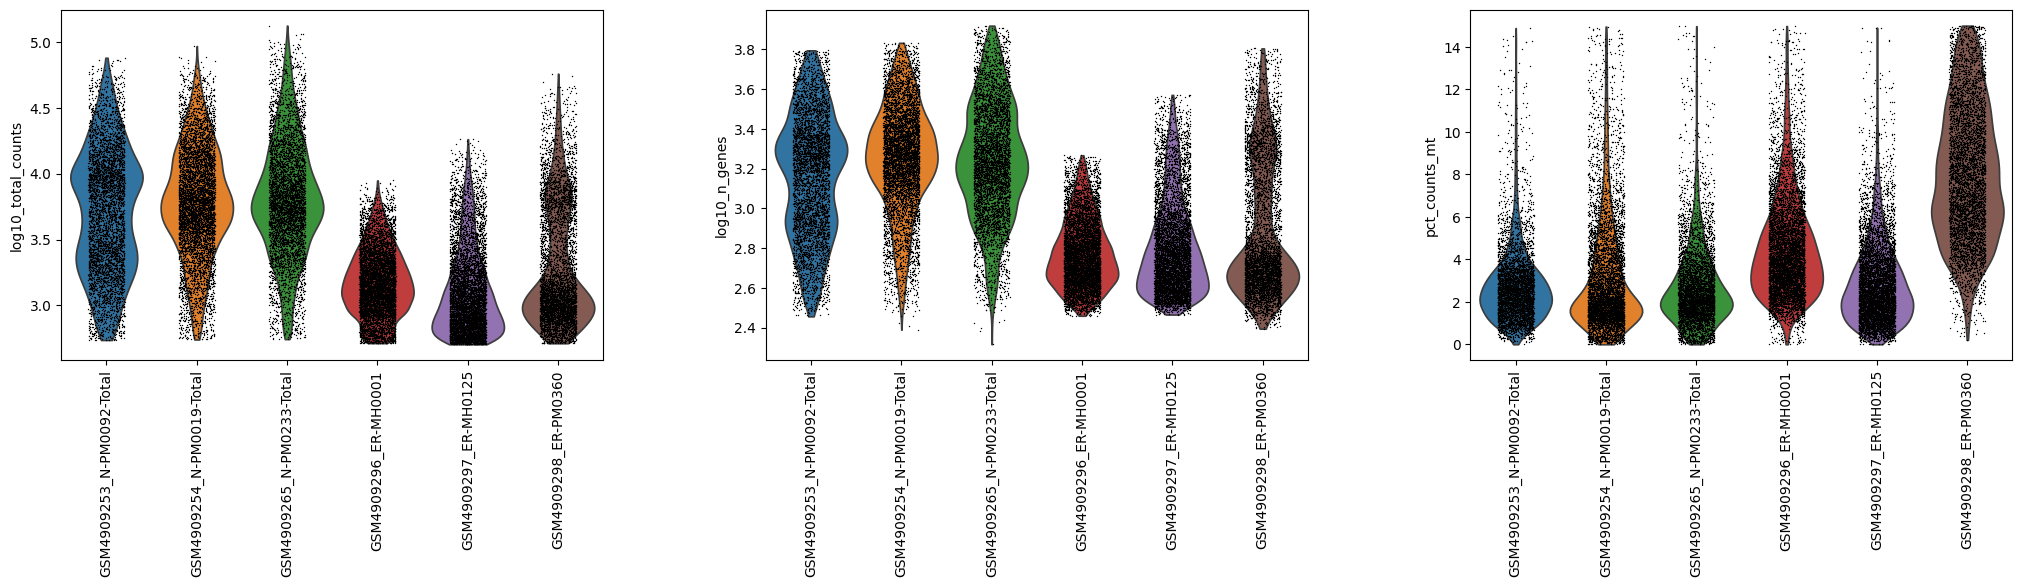

In [ ]:
# Compare cell retention before and after quality control.
before = adata.obs["sample_id"].value_counts().rename("before")
after = adata_qc.obs["sample_id"].value_counts().rename("after")

summary = pd.concat([before, after], axis=1).fillna(0).astype(int)
summary["removed"] = summary["before"] - summary["after"]
summary["pct_removed"] = (
    summary["removed"] / summary["before"] * 100
).round(2)

display(summary.sort_values("pct_removed", ascending=False))

# Recalculate QC metrics on the filtered object for final visualization.
sc.pp.calculate_qc_metrics(
    adata_qc,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True,
)

sc.pl.violin(
    adata_qc,
    ["log10_total_counts", "log10_n_genes", "pct_counts_mt"],
    groupby="sample_id",
    rotation=90,
    jitter=0.2,
    multi_panel=True,
)

In [ ]:
# Save the QC-filtered AnnData object for downstream analysis.
out_path = f"{PROJECT_DIR}/adata_step2_qc.h5ad"
adata_qc.write_h5ad(out_path)

print(f"Saved QC-filtered dataset: {out_path}")

Saved: /content/drive/MyDrive/bioinformatics final project/adata_step2_qc.h5ad


In [ ]:
# Verify the mitochondrial-read distribution after filtering.
adata_qc.obs["pct_counts_mt"].describe()

,pct_counts_mt
count,36490.000000
mean,4.033509
std,3.014351
min,0.000000
25%,1.865124
50%,3.167278
75%,5.356769
max,15.000000


In [ ]:
# Check the minimum number of detected genes among retained cells.
adata_qc.obs["n_genes_by_counts"].min()

204

<a id="step-3"></a>
## Step 3 — Normalization and Feature Selection

Counts are retained in a dedicated layer, followed by library-size normalization to 10,000 counts per cell and log transformation. The Seurat v3 method identifies 2,000 highly variable genes using sample-aware selection. The resulting expression matrix is scaled for downstream dimensionality reduction.

In [ ]:
# Load the QC-filtered dataset and preserve the original counts.
import scanpy as sc
import numpy as np
from pathlib import Path



adata = sc.read_h5ad(
    str(PROJECT_DIR / "adata_step2_qc.h5ad")
)

adata.layers["counts"] = adata.X.copy()
adata.var_names_make_unique()

In [ ]:
# Normalize library sizes and log-transform gene expression.
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Preserve log-normalized expression for downstream interpretation.
adata.raw = adata

In [ ]:
# Identify highly variable genes using the original count matrix.


sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat_v3",
    batch_key="sample_id",
    layer="counts",
)

int(adata.var["highly_variable"].sum())

2000

### Highly Variable Gene Selection

Highly variable genes capture informative expression differences across cells. The Seurat v3 method selects 2,000 genes using raw counts, with sample identity incorporated into the selection procedure. The following visualizations summarize the mean–variance relationship and highlight the selected features.

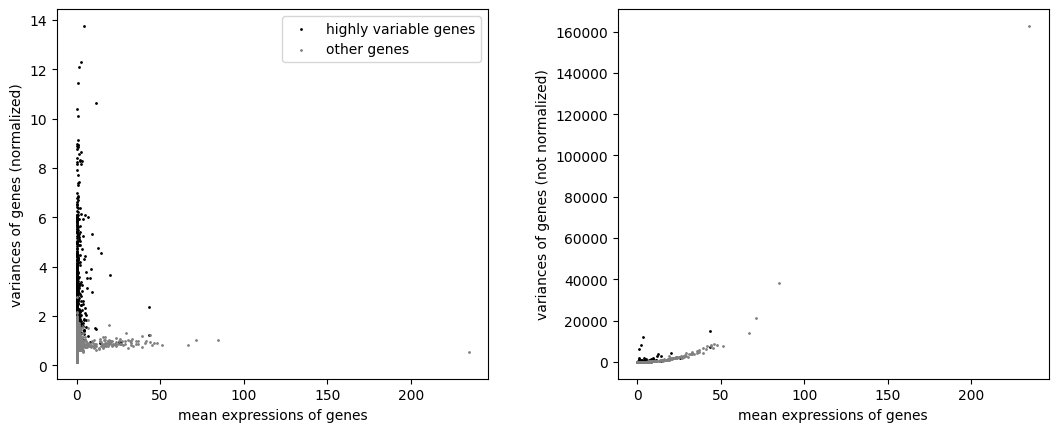

AnnData object with n_obs × n_vars = 36490 × 2000
    obs: 'gsm', 'sample_id', 'condition', 'patient_id', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log10_total_counts', 'log10_n_genes'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'sample_id_colors', 'log1p', 'hvg'
    layers: 'counts'

In [ ]:
# Visualize highly variable gene selection and create the subset.
sc.pl.highly_variable_genes(adata)

adata_hvg = adata[:, adata.var["highly_variable"]].copy()
adata_hvg

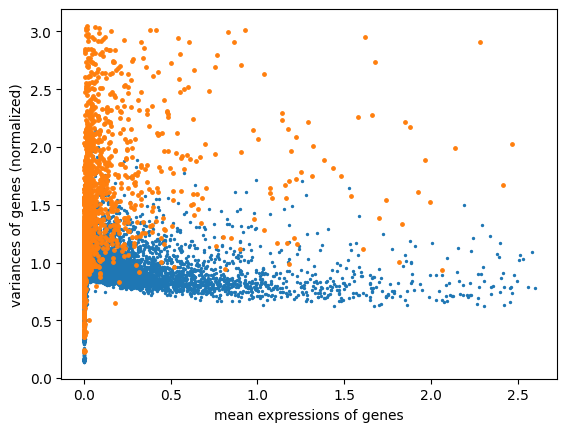

In [ ]:
# Highlight highly variable genes in the mean–variance plot.
import matplotlib.pyplot as plt

hvg_plot = adata.var[
    ["means", "variances_norm", "highly_variable"]
].dropna().copy()

# Trim extreme values for visualization only.
mean_cutoff = hvg_plot["means"].quantile(0.995)
variance_cutoff = hvg_plot["variances_norm"].quantile(0.995)

hvg_plot = hvg_plot[
    (hvg_plot["means"] <= mean_cutoff)
    & (hvg_plot["variances_norm"] <= variance_cutoff)
]

selected = hvg_plot["highly_variable"].astype(bool)

plt.figure(figsize=(7, 5))

plt.scatter(
    hvg_plot.loc[~selected, "means"],
    hvg_plot.loc[~selected, "variances_norm"],
    s=3,
    alpha=0.5,
    label="Other genes",
)

plt.scatter(
    hvg_plot.loc[selected, "means"],
    hvg_plot.loc[selected, "variances_norm"],
    s=5,
    alpha=0.8,
    label="Highly variable genes",
)

plt.xlabel("Mean expression")
plt.ylabel("Normalized variance")
plt.title("Highly variable gene selection")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
# Scale highly variable genes for downstream dimensionality reduction.
# Clip extreme scaled values at 10.
sc.pp.scale(adata_hvg, max_value=10)

/usr/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [ ]:
# Save the scaled, highly variable gene matrix for Step 4.
out_path = str(PROJECT_DIR / "adata_step3_hvg.h5ad")
adata_hvg.write_h5ad(out_path)

print("Saved:", out_path)

Saved: /content/drive/MyDrive/bioinformatics final project/adata_step3_hvg.h5ad


<a id="step-4"></a>
## Step 4 — Dimensionality Reduction and Initial Clustering

Principal component analysis (PCA) summarizes variation across the selected genes, while UMAP provides a two-dimensional representation of cellular structure. A neighborhood graph based on 30 principal components and 15 neighbors is used to examine Leiden clustering at two resolutions before batch correction.

In [ ]:
# Load the scaled, highly variable gene matrix from Step 3.
import scanpy as sc
import pandas as pd
from pathlib import Path


adata = sc.read_h5ad(
    PROJECT_DIR / "adata_step3_hvg.h5ad"
)

adata

AnnData object with n_obs × n_vars = 36490 × 2000
    obs: 'gsm', 'sample_id', 'condition', 'patient_id', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log10_total_counts', 'log10_n_genes'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std'
    uns: 'hvg', 'log1p', 'sample_id_colors'
    layers: 'counts'

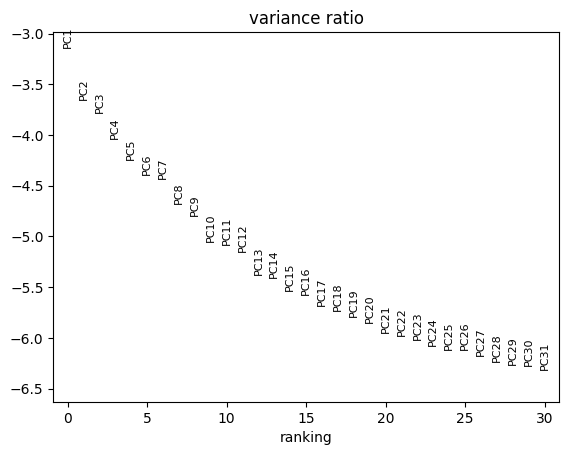

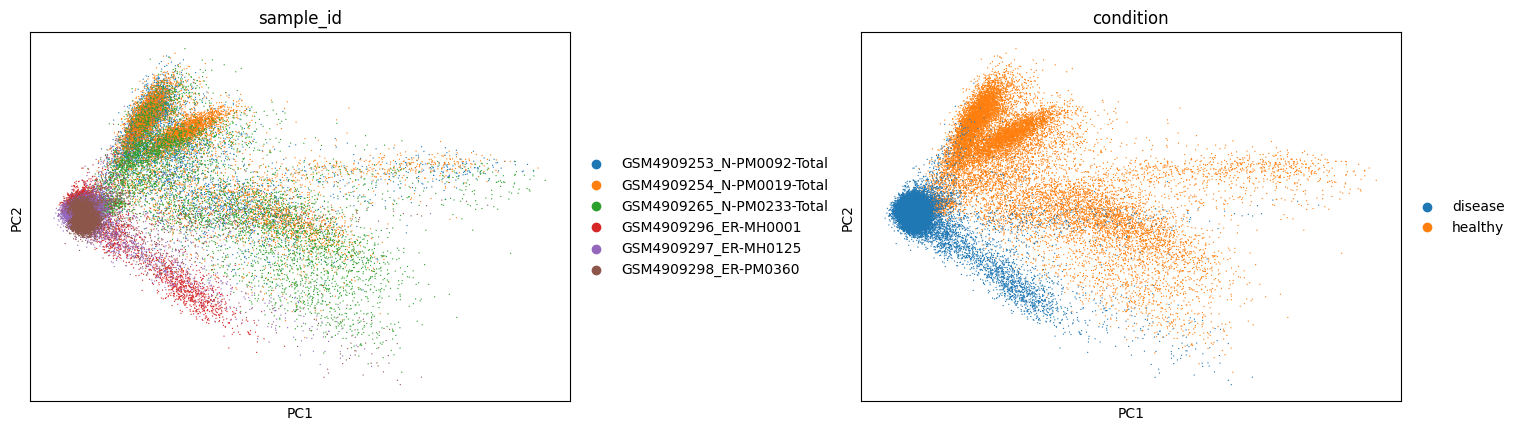

In [ ]:
# Compute PCA on the scaled expression matrix.
sc.tl.pca(adata, svd_solver="arpack")

# Examine the variance explained by successive principal components.
sc.pl.pca_variance_ratio(adata, log=True)

# Visualize the PCA embedding by sample and condition.
sc.pl.pca(
    adata,
    color=["sample_id", "condition"],
    wspace=0.4,
)

### Neighborhood Graph and UMAP

A nearest-neighbor graph is constructed using the first 30 principal components and 15 neighbors per cell. UMAP projects the resulting neighborhood structure into two dimensions for visualization, with sample and condition labels used to examine the distribution of cells.

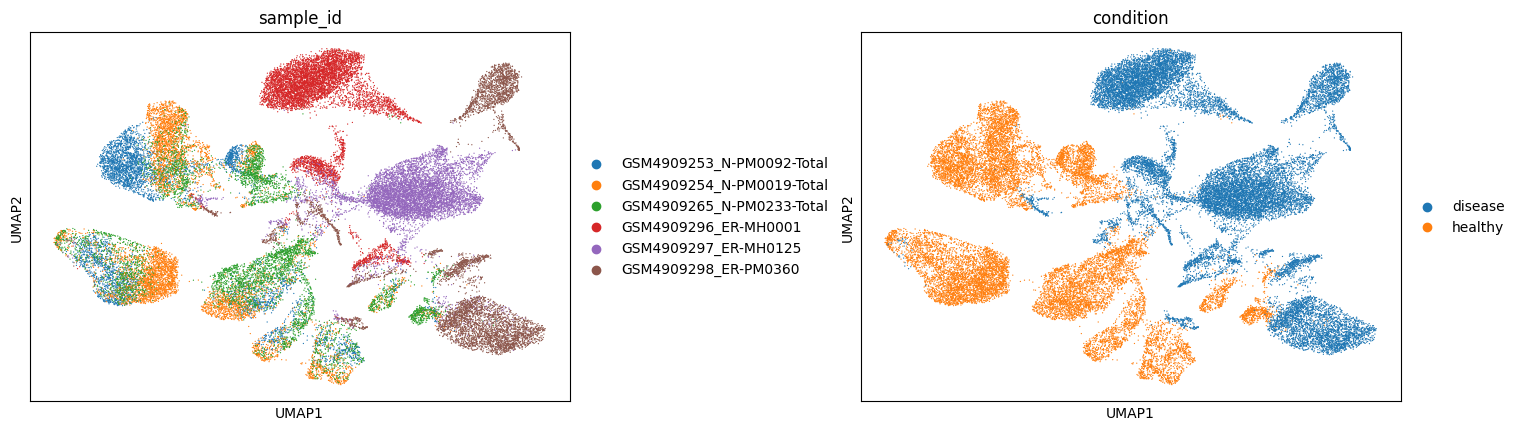

In [ ]:
# Construct the neighborhood graph in PCA space.
n_pcs = 30
n_neighbors = 15

sc.pp.neighbors(
    adata,
    n_neighbors=n_neighbors,
    n_pcs=n_pcs,
)

# Compute and visualize the two-dimensional UMAP embedding.
sc.tl.umap(adata)

sc.pl.umap(
    adata,
    color=["sample_id", "condition"],
    wspace=0.4,
)

### Preliminary Leiden Clustering

Leiden clustering is evaluated at resolutions 0.5 and 1.0 to compare different levels of cluster granularity. UMAP plots and condition-stratified cluster counts provide complementary views of the resulting partitions. These preliminary clusters are used to examine the data before batch-aware graph construction.

/tmp/ipython-input-620737895.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.5, key_added="leiden_r05")
/tmp/ipython-input-620737895.py:3: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=1.0, key_added="leiden_r1

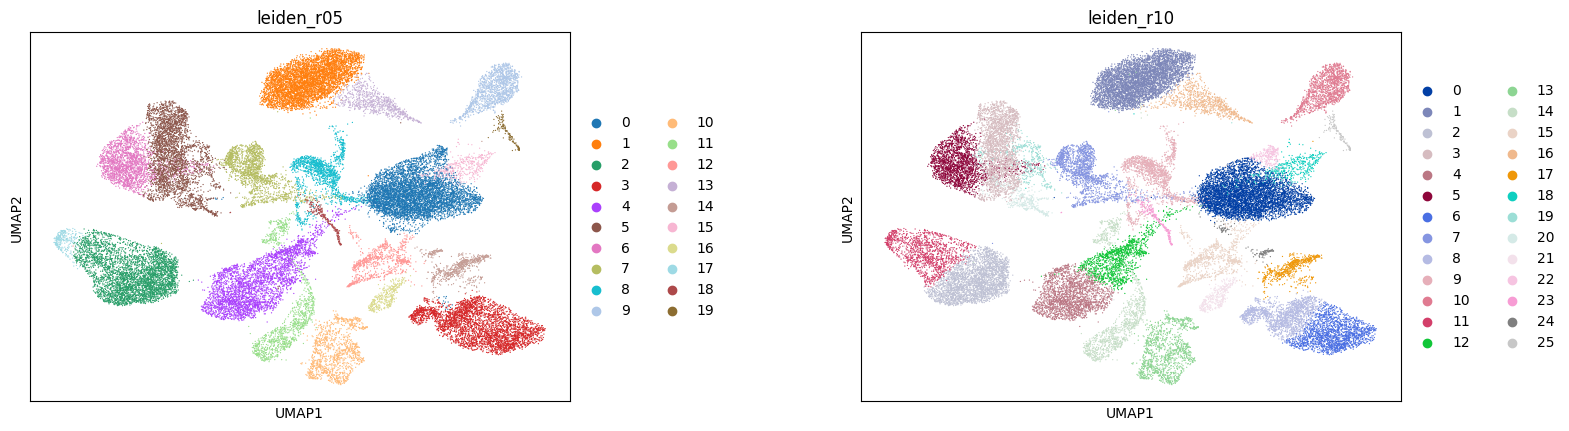

condition,disease,healthy
leiden_r05,,
0,5619,3
1,4941,15
2,1,3814
3,2998,477
4,90,3139
5,154,2936
6,0,2002
7,76,1551
8,1362,3


condition,disease,healthy
leiden_r10,,
0,5144,2
1,4891,13
2,1,2799
3,6,2320
4,0,1986
5,0,1976
6,1848,4
7,91,1551
8,1166,473


In [ ]:
# Compare Leiden clustering at two resolutions.
sc.tl.leiden(
    adata,
    resolution=0.5,
    key_added="leiden_r05",
)

sc.tl.leiden(
    adata,
    resolution=1.0,
    key_added="leiden_r10",
)

# Visualize the two clustering solutions on the same UMAP embedding.
sc.pl.umap(
    adata,
    color=["leiden_r05", "leiden_r10"],
    wspace=0.4,
)

# Examine condition composition within each clustering solution.
ct_r05 = pd.crosstab(
    adata.obs["leiden_r05"],
    adata.obs["condition"],
)

ct_r10 = pd.crosstab(
    adata.obs["leiden_r10"],
    adata.obs["condition"],
)

display(ct_r05)
display(ct_r10)

In [ ]:
# Save the PCA, UMAP, and preliminary clustering results.
out_path = PROJECT_DIR / "adata_step4_clustered.h5ad"

adata.write_h5ad(out_path)

print(f"Saved: {out_path}")

Saved: /content/drive/MyDrive/bioinformatics final project/adata_step4_clustered.h5ad


<a id="step-5"></a>
## Step 5 — Batch-Aware Clustering

BBKNN constructs a sample-balanced neighborhood graph using sample identity as the batch variable. UMAP and Leiden clustering are recalculated on the corrected graph. Cluster composition and canonical marker expression are then examined to support downstream biological interpretation.

In [ ]:
# Load the PCA, UMAP, and preliminary clustering results from Step 4.
import scanpy as sc
import pandas as pd
from pathlib import Path

adata = sc.read_h5ad(
    PROJECT_DIR / "adata_step4_clustered.h5ad"
)

adata

AnnData object with n_obs × n_vars = 36490 × 2000
    obs: 'gsm', 'sample_id', 'condition', 'patient_id', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log10_total_counts', 'log10_n_genes', 'leiden_r05', 'leiden_r10'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std'
    uns: 'condition_colors', 'hvg', 'leiden_r05', 'leiden_r05_colors', 'leiden_r10', 'leiden_r10_colors', 'log1p', 'neighbors', 'pca', 'sample_id_colors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

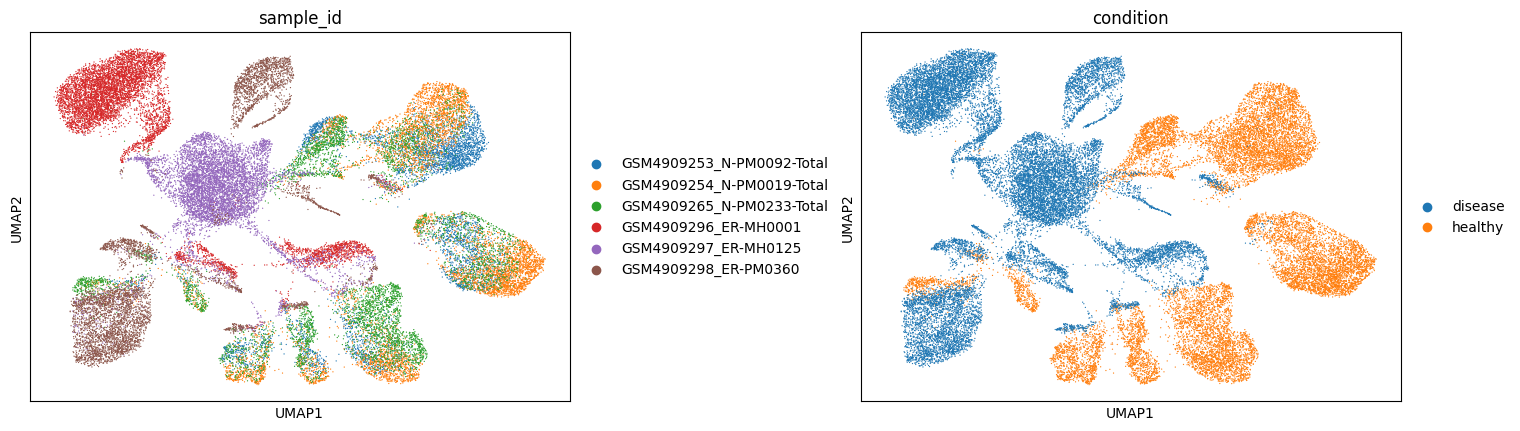

In [ ]:
# Construct a batch-balanced neighborhood graph across samples.
import bbknn

bbknn.bbknn(
    adata,
    batch_key="sample_id",
    neighbors_within_batch=15,
    n_pcs=30,
)

# Recompute UMAP using the BBKNN neighborhood graph.
sc.tl.umap(adata)

# Examine the embedding by sample and biological condition.
sc.pl.umap(
    adata,
    color=["sample_id", "condition"],
    wspace=0.4,
)

/tmp/ipython-input-3646377646.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.8, key_added="leiden_bbknn")


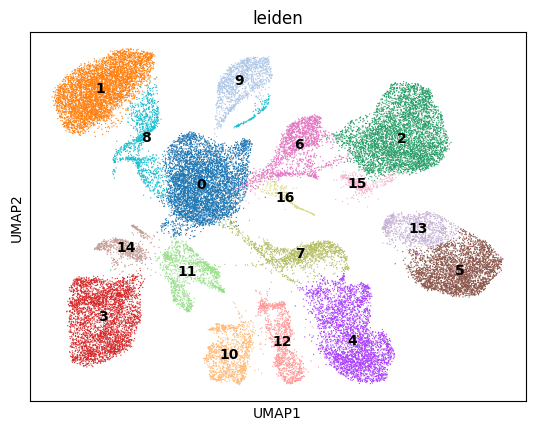

In [ ]:
# Identify cell clusters using the BBKNN neighborhood graph.
sc.tl.leiden(
    adata,
    resolution=0.8,
    key_added="leiden_bbknn",
)

# Use a consistent cluster label for downstream analyses.
adata.obs["leiden"] = adata.obs["leiden_bbknn"].astype(str)

# Visualize the final cluster assignments on UMAP.
sc.pl.umap(
    adata,
    color="leiden",
    legend_loc="on data",
)

In [ ]:
# Summarize healthy and tumor cell counts within each cluster.
cluster_condition_counts = pd.crosstab(
    adata.obs["leiden"],
    adata.obs["condition"],
)

display(cluster_condition_counts)

condition,disease,healthy
leiden,,
0,5516,1
1,4949,13
2,8,4625
3,3024,479
4,126,3142
5,1,3111
6,108,1603
7,1340,3
8,1317,8


### Cluster Marker Discovery

Marker genes are ranked for each Leiden cluster using Wilcoxon testing on the log-normalized expression data retained in `adata.raw`. These rankings, together with canonical marker-gene expression, provide the basis for the cell-type annotation developed in Step 6.

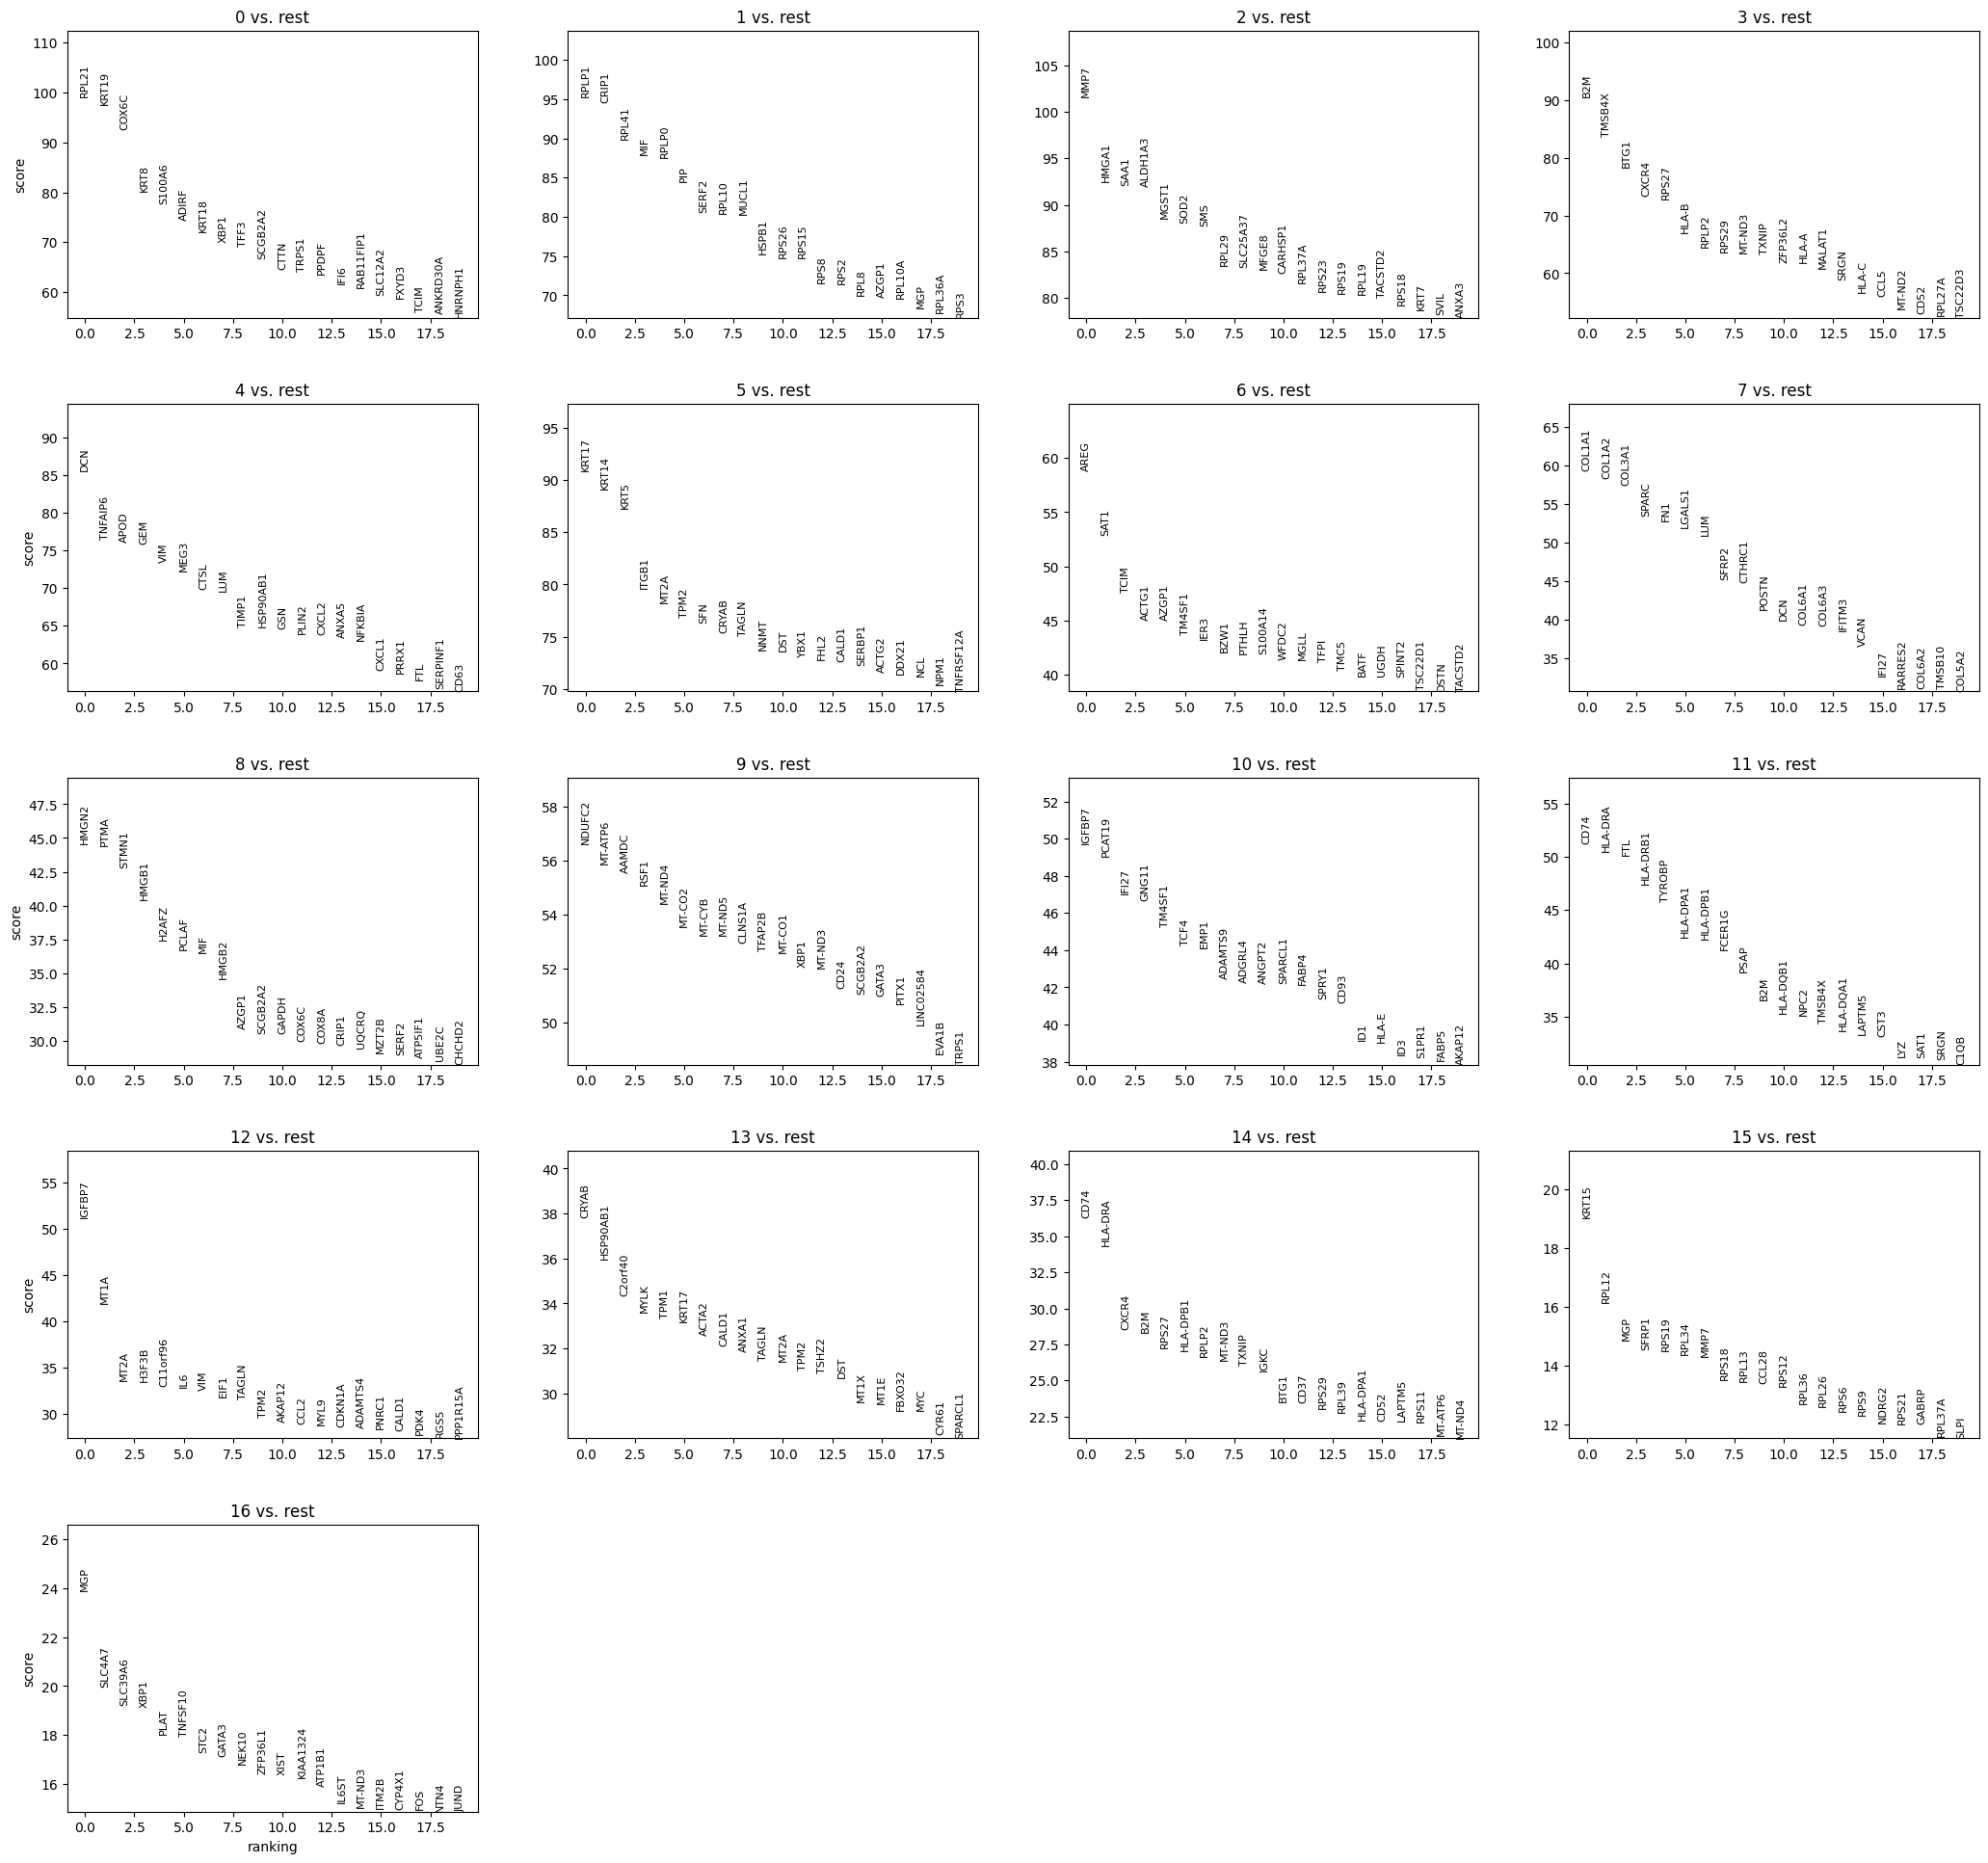

In [ ]:
# Rank marker genes for each Leiden cluster.
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden",
    method="wilcoxon",
    use_raw=True,
)

# Visualize the top-ranked genes for each cluster.
sc.pl.rank_genes_groups(
    adata,
    n_genes=20,
    sharey=False,
)

In [ ]:
# Extract ranked marker statistics for all clusters.
markers = sc.get.rank_genes_groups_df(
    adata,
    group=None,
)

# Preview the leading marker records.
display(markers.head(20))

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,RPL21,99.108177,1.472457,0.0,0.0
1,0,KRT19,97.646858,4.213987,0.0,0.0
2,0,COX6C,92.577301,3.666829,0.0,0.0
3,0,KRT8,80.131065,3.175187,0.0,0.0
4,0,S100A6,77.745300,2.688442,0.0,0.0
5,0,ADIRF,74.363358,3.305833,0.0,0.0
6,0,KRT18,72.071434,2.717115,0.0,0.0
7,0,XBP1,69.911606,2.475127,0.0,0.0
8,0,TFF3,69.272789,3.747709,0.0,0.0
9,0,SCGB2A2,66.661125,3.846560,0.0,0.0


In [ ]:
# Export the cluster marker rankings for downstream analysis.
markers_path = PROJECT_DIR / "markers_step5_bbknn.csv"

markers.to_csv(markers_path, index=False)

print(f"Saved marker table: {markers_path}")

Saved: /content/drive/MyDrive/bioinformatics final project/markers_step5_bbknn.csv


,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,RPL21,99.108177,1.472457,0.0,0.0
1,0,KRT19,97.646858,4.213987,0.0,0.0
2,0,COX6C,92.577301,3.666829,0.0,0.0
3,0,KRT8,80.131065,3.175187,0.0,0.0
4,0,S100A6,77.745300,2.688442,0.0,0.0
5,0,ADIRF,74.363358,3.305833,0.0,0.0
6,0,KRT18,72.071434,2.717115,0.0,0.0
7,0,XBP1,69.911606,2.475127,0.0,0.0
8,0,TFF3,69.272789,3.747709,0.0,0.0
9,0,SCGB2A2,66.661125,3.846560,0.0,0.0


In [ ]:
# Define canonical markers for major mammary tissue populations.
marker_panel = [
    "EPCAM", "KRT8", "KRT18", "KRT19",  # Epithelial
    "COL1A1", "COL1A2", "DCN", "LUM",   # Stromal
    "PECAM1", "VWF",                     # Endothelial
    "PTPRC", "CD3D", "CD3E", "MS4A1",   # Immune
    "NKG7", "LYZ",                       # Immune subpopulations
    "MKI67", "TOP2A",                    # Proliferation
]

# Retain markers available in the selected expression matrix.
present = [
    gene for gene in marker_panel
    if gene in adata.var_names
]

present

['KRT19',
 'COL1A1',
 'COL1A2',
 'DCN',
 'LUM',
 'PECAM1',
 'VWF',
 'CD3D',
 'MS4A1',
 'NKG7',
 'LYZ',
 'MKI67',
 'TOP2A']

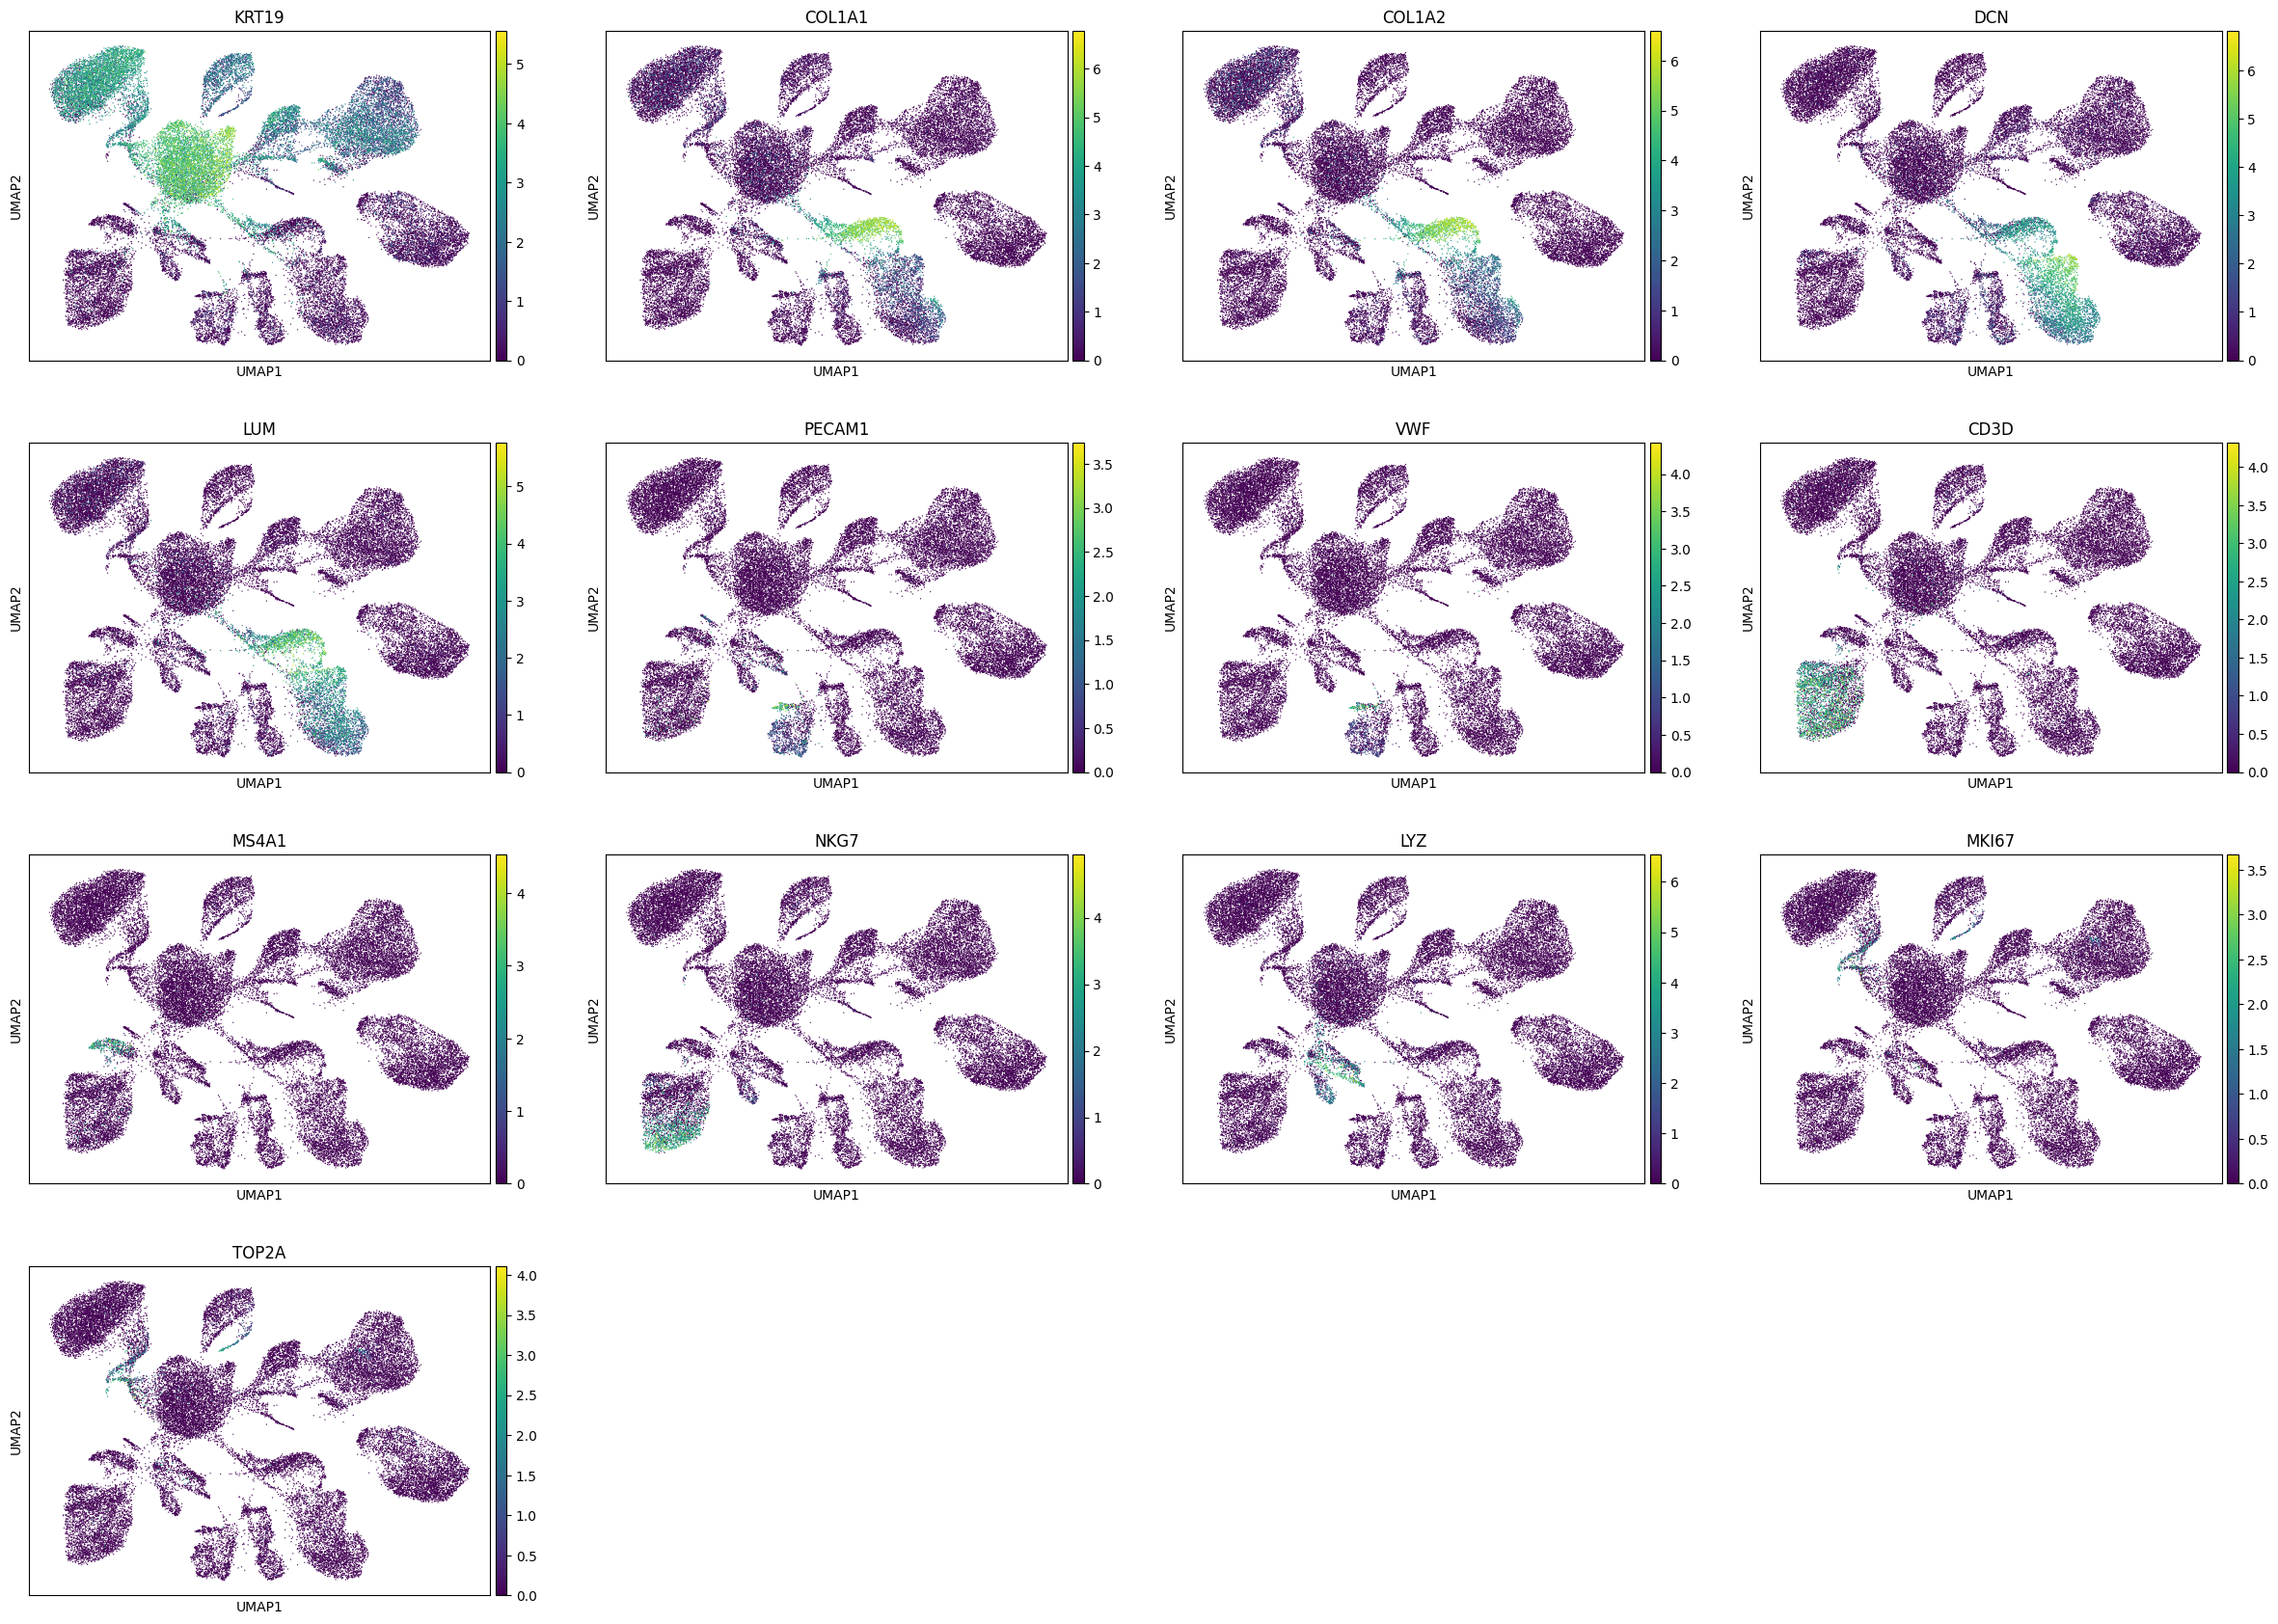

In [ ]:
# Visualize canonical marker expression across the UMAP embedding.
sc.pl.umap(
    adata,
    color=present,
    ncols=4,
)

In [ ]:
# Save the BBKNN-integrated object for downstream annotation.
out_path = PROJECT_DIR / "adata_step5_bbknn.h5ad"

adata.write_h5ad(out_path)

print(f"Saved clustered dataset: {out_path}")

Saved: /content/drive/MyDrive/bioinformatics final project/adata_step5_bbknn.h5ad


<a id="step-6"></a>
## Step 6 — Cell-Type Annotation and Differential Expression

The 17 transcriptional clusters are assigned descriptive cell-type labels using cluster marker rankings and canonical marker genes. Within each eligible cell type, Wilcoxon tests compare healthy and ER-positive tumor cells, requiring at least 50 cells per condition. Adjusted p-values and fold changes are used to prioritize candidate differentially expressed genes.

In [ ]:
# Load the BBKNN-integrated dataset with final cluster assignments.
import scanpy as sc
import pandas as pd
import numpy as np
from pathlib import Path


adata = sc.read_h5ad(
    PROJECT_DIR / "adata_step5_bbknn.h5ad"
)

adata

AnnData object with n_obs × n_vars = 36490 × 2000
    obs: 'gsm', 'sample_id', 'condition', 'patient_id', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log10_total_counts', 'log10_n_genes', 'leiden_r05', 'leiden_r10', 'leiden_bbknn', 'leiden'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std'
    uns: 'condition_colors', 'hvg', 'leiden_bbknn', 'leiden_colors', 'leiden_r05', 'leiden_r05_colors', 'leiden_r10', 'leiden_r10_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'sample_id_colors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [ ]:
# Confirm that log-normalized expression is available for marker analysis.
if adata.raw is None:
    raise ValueError(
        "adata.raw is missing. Load the Step 5 object with "
        "the preserved log-normalized expression data."
    )

print("Log-normalized expression is available.")

In [ ]:
# Retrieve ranked marker genes for each Leiden cluster.
markers = sc.get.rank_genes_groups_df(
    adata,
    group=None,
)

# Display the five highest-ranked markers per cluster.
top5 = (
    markers
    .sort_values(
        ["group", "scores"],
        ascending=[True, False],
    )
    .groupby("group", observed=False)
    .head(5)
    .reset_index(drop=True)
)

display(top5)

/tmp/ipython-input-3227435608.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")


,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,RPL21,99.108177,1.472457,0.000000e+00,0.000000e+00
1,0,KRT19,97.646858,4.213987,0.000000e+00,0.000000e+00
2,0,COX6C,92.577301,3.666829,0.000000e+00,0.000000e+00
3,0,KRT8,80.131065,3.175187,0.000000e+00,0.000000e+00
4,0,S100A6,77.745300,2.688442,0.000000e+00,0.000000e+00
...,...,...,...,...,...,...
386656,16,MGP,23.897497,5.271348,3.251811e-126,7.858327e-122
386657,16,SLC4A7,19.953089,4.227366,1.409061e-88,1.702568e-84
386658,16,SLC39A6,19.206646,3.943275,3.256332e-82,2.623084e-78
386659,16,XBP1,19.156067,2.931125,8.614325e-82,5.204344e-78


In [ ]:
# Assign descriptive cell-type labels to the 17 Leiden clusters.
# Labels are informed by the ranked cluster markers and
# canonical marker-gene signatures.

cluster_to_type = {
    "0": "Epithelial_Luminal",
    "1": "Epithelial_Luminal_PIP",
    "2": "Epithelial_Inflammatory_Stress",
    "3": "Lymphocyte_like",
    "4": "Fibroblast_APOD",
    "5": "Epithelial_Basal_Myoepithelial",
    "6": "Epithelial_TM4SF1_AREG",
    "7": "Fibroblast_CAF_Activated",
    "8": "Cycling_Proliferating",
    "9": "HighMT_TumorState",
    "10": "Endothelial",
    "11": "Myeloid_APC",
    "12": "Stromal_IL6_TAGLN",
    "13": "SmoothMuscle_Pericyte",
    "14": "B_cell_APC",
    "15": "Epithelial_Basal_Progenitor",
    "16": "Epithelial_Luminal_State2",
}

In [ ]:
# Map Leiden cluster identifiers to descriptive cell-type labels.
cluster_labels = adata.obs["leiden"].astype(str)

adata.obs["cell_type"] = cluster_labels.map(cluster_to_type)
adata.obs["cell_type"] = adata.obs["cell_type"].astype("object")

# Retain a traceable label if any cluster is not mapped.
unmapped = adata.obs["cell_type"].isna()

adata.obs.loc[unmapped, "cell_type"] = (
    "Unknown_" + cluster_labels.loc[unmapped]
)

# Summarize the number of cells assigned to each population.
cell_type_counts = adata.obs["cell_type"].value_counts()

display(cell_type_counts)

,count
cell_type,
Epithelial_Luminal,5517
Epithelial_Luminal_PIP,4962
Epithelial_Inflammatory_Stress,4633
Lymphocyte_like,3503
Fibroblast_APOD,3268
Epithelial_Basal_Myoepithelial,3112
Epithelial_TM4SF1_AREG,1711
Fibroblast_CAF_Activated,1343
Cycling_Proliferating,1325


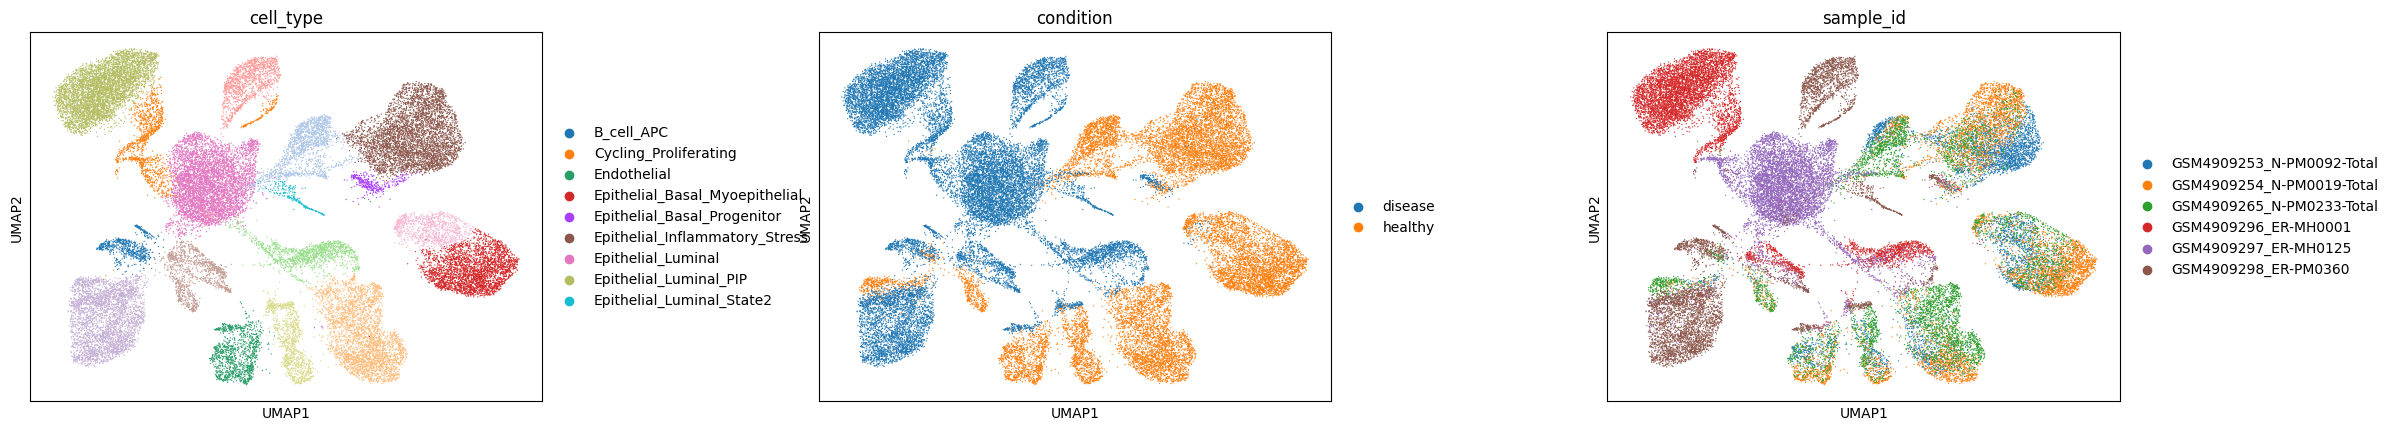

In [ ]:
# Visualize cell-type annotations alongside sample and condition labels.
sc.pl.umap(
    adata,
    color=["cell_type", "condition", "sample_id"],
    wspace=0.4,
)

In [ ]:
# Compare cell-type abundance across healthy and tumor conditions.
ct = pd.crosstab(
    adata.obs["cell_type"],
    adata.obs["condition"],
)

display(ct)

condition,disease,healthy
cell_type,,
B_cell_APC,585,86
Cycling_Proliferating,1317,8
Endothelial,171,1059
Epithelial_Basal_Myoepithelial,1,3111
Epithelial_Basal_Progenitor,156,234
Epithelial_Inflammatory_Stress,8,4625
Epithelial_Luminal,5516,1
Epithelial_Luminal_PIP,4949,13
Epithelial_Luminal_State2,218,4


### Cell-Type-Specific Differential Expression

Within each annotated cell type, healthy and ER-positive tumor cells are compared using the Wilcoxon rank-sum test. Analysis is restricted to populations containing at least 50 cells from each condition. Benjamini–Hochberg-adjusted p-values and absolute log-fold changes are used to prioritize disease-associated expression differences.

In [ ]:
# Compare healthy and tumor cells within each eligible cell type.
min_cells_per_group = 50

deg_results = []
valid_types = []

for cell_type in sorted(adata.obs["cell_type"].unique()):
    subset = adata[
        adata.obs["cell_type"] == cell_type
    ].copy()

    n_healthy = int(
        (subset.obs["condition"] == "healthy").sum()
    )
    n_disease = int(
        (subset.obs["condition"] == "disease").sum()
    )

    # Require adequate cell counts in both conditions.
    if (
        n_healthy < min_cells_per_group
        or n_disease < min_cells_per_group
    ):
        continue

    valid_types.append(
        (cell_type, n_healthy, n_disease)
    )

    # Rank genes higher in disease relative to healthy cells.
    sc.tl.rank_genes_groups(
        subset,
        groupby="condition",
        groups=["disease"],
        reference="healthy",
        method="wilcoxon",
        corr_method="benjamini-hochberg",
        use_raw=True,
    )

    deg = sc.get.rank_genes_groups_df(
        subset,
        group="disease",
    )

    # Record the population and group sizes alongside each gene.
    deg.insert(0, "cell_type", cell_type)
    deg.insert(1, "n_healthy", n_healthy)
    deg.insert(2, "n_disease", n_disease)

    deg_results.append(deg)

print("Eligible cell types:", len(valid_types))
display(pd.DataFrame(
    valid_types,
    columns=["cell_type", "n_healthy", "n_disease"],
))

([('B_cell_APC', 86, 585),
  ('Endothelial', 1059, 171),
  ('Epithelial_Basal_Progenitor', 234, 156),
  ('Epithelial_TM4SF1_AREG', 1603, 108),
  ('Fibroblast_APOD', 3142, 126),
  ('Lymphocyte_like', 479, 3024),
  ('Myeloid_APC', 366, 791),
  ('Stromal_IL6_TAGLN', 961, 173)],
 8)

In [ ]:
# Combine the differential-expression results across eligible cell types.
if not deg_results:
    raise ValueError(
        "No cell types met the minimum cell-count criterion "
        "for differential-expression analysis."
    )

deg_all = pd.concat(
    deg_results,
    ignore_index=True,
)

# Export the complete gene-level results table.
deg_path = (
    PROJECT_DIR
    / "step6_DEGs_by_celltype_disease_vs_healthy.csv"
)

deg_all.to_csv(deg_path, index=False)

print(f"Saved differential-expression results: {deg_path}")
display(deg_all.head(20))

Saved: /content/drive/MyDrive/bioinformatics final project/step6_DEGs_by_celltype_disease_vs_healthy.csv


,cell_type,n_healthy,n_disease,names,scores,logfoldchanges,pvals,pvals_adj
0,B_cell_APC,86,585,TMSB4X,11.877872,2.558893,1.542443e-32,1.863734e-28
1,B_cell_APC,86,585,MT-ND4,11.157586,1.857088,6.575304e-29,4.712044e-25
2,B_cell_APC,86,585,MT-ND3,11.142393,2.080298,7.799460e-29,4.712044e-25
3,B_cell_APC,86,585,MT-CO2,10.744717,1.780486,6.275419e-27,3.033036e-23
4,B_cell_APC,86,585,MT-CYB,10.213290,1.788265,1.729012e-24,5.969044e-21
5,B_cell_APC,86,585,MT-ATP6,10.048262,1.795925,9.350246e-24,2.824476e-20
6,B_cell_APC,86,585,MT-CO3,9.656543,1.477856,4.611663e-22,1.238283e-18
7,B_cell_APC,86,585,MT-CO1,8.682160,1.129708,3.883221e-18,8.531084e-15
8,B_cell_APC,86,585,CD52,8.120050,3.696968,4.659882e-16,8.043622e-13
9,B_cell_APC,86,585,TXNIP,8.100688,2.346515,5.464907e-16,8.804330e-13


### Prioritization of Differentially Expressed Genes

Candidate genes are prioritized using adjusted p-values below 0.05 and absolute log-fold changes of at least 0.5. The leading significant genes from each eligible cell type are exported as a compact summary for downstream feature selection and biological interpretation.

In [ ]:
# Define the significance and effect-size thresholds.
padj_cut = 0.05
logfc_cut = 0.5

deg_sig = deg_all.loc[
    (deg_all["pvals_adj"] < padj_cut)
    & (deg_all["logfoldchanges"].abs() >= logfc_cut)
].copy()

# Retain the ten highest-ranked significant genes per cell type.
top10 = (
    deg_sig
    .sort_values(
        ["cell_type", "scores"],
        ascending=[True, False],
    )
    .groupby("cell_type", observed=False)
    .head(10)
    .reset_index(drop=True)
)

# Export the filtered gene table for downstream analysis.
top10_path = (
    PROJECT_DIR
    / "step6_DEGs_by_celltype_top10_sig.csv"
)

top10.to_csv(top10_path, index=False)

print(f"Saved significant-gene summary: {top10_path}")
display(top10)

<a id="step-7"></a>
## Step 7 — Sample-Level Feature Engineering and Model Training

Significant cell-type-specific DEGs are selected using adjusted p-value and fold-change criteria, with up to 50 genes selected per eligible cell type. The resulting 244-gene signature is represented across eight cell types, yielding 1,952 cell-type-specific expression features per sample. Mean log-normalized expression is summarized by sample and cell type, and L2-regularized logistic regression is compared with a Random Forest classifier.

In [ ]:
# Load the clustered expression data and differential-expression results.
import scanpy as sc
import pandas as pd
import numpy as np
from pathlib import Path


adata = sc.read_h5ad(
    PROJECT_DIR / "adata_step5_bbknn.h5ad"
)

deg_all = pd.read_csv(
    PROJECT_DIR / "step6_DEGs_by_celltype_disease_vs_healthy.csv"
)

adata

AnnData object with n_obs × n_vars = 36490 × 2000
    obs: 'gsm', 'sample_id', 'condition', 'patient_id', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log10_total_counts', 'log10_n_genes', 'leiden_r05', 'leiden_r10', 'leiden_bbknn', 'leiden'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std'
    uns: 'condition_colors', 'hvg', 'leiden_bbknn', 'leiden_colors', 'leiden_r05', 'leiden_r05_colors', 'leiden_r10', 'leiden_r10_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'sample_id_colors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [ ]:
# Restore the cluster-to-cell-type mapping used in Step 6.
cluster_to_type = {
    "0": "Epithelial_Luminal",
    "1": "Epithelial_Luminal_PIP",
    "2": "Epithelial_Inflammatory_Stress",
    "3": "Lymphocyte_like",
    "4": "Fibroblast_APOD",
    "5": "Epithelial_Basal_Myoepithelial",
    "6": "Epithelial_TM4SF1_AREG",
    "7": "Fibroblast_CAF_Activated",
    "8": "Cycling_Proliferating",
    "9": "HighMT_TumorState",
    "10": "Endothelial",
    "11": "Myeloid_APC",
    "12": "Stromal_IL6_TAGLN",
    "13": "SmoothMuscle_Pericyte",
    "14": "B_cell_APC",
    "15": "Epithelial_Basal_Progenitor",
    "16": "Epithelial_Luminal_State2",
}

cluster_labels = adata.obs["leiden"].astype(str)
adata.obs["cell_type"] = cluster_labels.map(cluster_to_type)

# Preserve an explicit label for any unmapped cluster.
missing = adata.obs["cell_type"].isna()
adata.obs.loc[missing, "cell_type"] = (
    "Unknown_" + cluster_labels.loc[missing]
)

adata.obs["cell_type"].value_counts()

,count
cell_type,
Epithelial_Luminal,5517
Epithelial_Luminal_PIP,4962
Epithelial_Inflammatory_Stress,4633
Lymphocyte_like,3503
Fibroblast_APOD,3268
Epithelial_Basal_Myoepithelial,3112
Epithelial_TM4SF1_AREG,1711
Fibroblast_CAF_Activated,1343
Cycling_Proliferating,1325


In [ ]:
# Restrict the analysis to the eight cell types used for feature selection.
valid_types = [
    "B_cell_APC",
    "Endothelial",
    "Epithelial_Basal_Progenitor",
    "Epithelial_TM4SF1_AREG",
    "Fibroblast_APOD",
    "Lymphocyte_like",
    "Myeloid_APC",
    "Stromal_IL6_TAGLN",
]

adata = adata[
    adata.obs["cell_type"].isin(valid_types)
].copy()

# Encode the prediction target: healthy = 0, disease = 1.
adata.obs["y"] = (
    adata.obs["condition"] == "disease"
).astype(int)

print("Samples:", sorted(adata.obs["sample_id"].unique()))
print("\nSample-level target labels:")
display(
    adata.obs[["sample_id", "condition", "y"]]
    .drop_duplicates()
    .sort_values("sample_id")
)

(['GSM4909253_N-PM0092-Total',
  'GSM4909254_N-PM0019-Total',
  'GSM4909265_N-PM0233-Total',
  'GSM4909296_ER-MH0001',
  'GSM4909297_ER-MH0125',
  'GSM4909298_ER-PM0360'],
 y
 0    7930
 1    5134
 Name: count, dtype: int64)

### Cell-Type-Specific Feature Selection

Genes are selected from the differential-expression results using adjusted p-value and fold-change thresholds. Up to 50 significant genes are retained per eligible cell type, and the selected genes are used to construct a consistent expression feature set across samples.

In [ ]:
# Select significant DEGs for the classification feature set.
top_n = 50
padj_cut = 0.05
logfc_cut = 0.5

deg_sig = deg_all.loc[
    (deg_all["pvals_adj"] < padj_cut)
    & (deg_all["logfoldchanges"].abs() >= logfc_cut)
].copy()

deg_sig = deg_sig[
    deg_sig["cell_type"].isin(valid_types)
].copy()

# Rank genes within each cell type and retain the top candidates.
deg_sig = deg_sig.sort_values(
    ["cell_type", "scores"],
    ascending=[True, False],
)

top_deg = (
    deg_sig
    .groupby("cell_type", observed=False)
    .head(top_n)
    .copy()
)

deg_genes = sorted(
    set(top_deg["names"].astype(str))
)

print("Unique selected genes:", len(deg_genes))
print("Example genes:", deg_genes[:20])

(244,
 ['A2M',
  'ACADVL',
  'ACTA2',
  'ACTB',
  'ACTG1',
  'ADGRL4',
  'ADIRF',
  'AIF1',
  'AMFR',
  'APOC1',
  'ATP5F1E',
  'ATP5MC2',
  'B2M',
  'BGN',
  'C1S',
  'C3',
  'CALD1',
  'CARMN',
  'CAV1',
  'CAVIN3'])

In [ ]:
# Aggregate mean log-normalized expression by sample and cell type.
if adata.raw is None:
    raise ValueError(
        "adata.raw is missing. Load the Step 5 object with "
        "the preserved log-normalized expression data."
    )

samples = sorted(adata.obs["sample_id"].unique())
celltypes = sorted(valid_types)

# Locate the selected genes in the preserved expression matrix.
var_index = pd.Index(adata.raw.var_names)
gene_indices = var_index.get_indexer(deg_genes)

available = gene_indices >= 0
available_genes = np.asarray(deg_genes)[available].tolist()
gene_indices = gene_indices[available]

X_rows = []
row_meta = []

for sample_id in samples:
    for cell_type in celltypes:
        mask = (
            (adata.obs["sample_id"] == sample_id)
            & (adata.obs["cell_type"] == cell_type)
        )

        n_cells = int(mask.sum())
        if n_cells == 0:
            continue

        # Extract only the selected genes to reduce memory use.
        subset = adata[mask]
        expression = subset.raw.X[:, gene_indices]

        if hasattr(expression, "toarray"):
            expression = expression.toarray()

        mean_expression = np.asarray(
            expression.mean(axis=0)
        ).reshape(-1)

        # Retain zero-valued columns if any selected gene is absent.
        feature_values = pd.Series(
            0.0,
            index=deg_genes,
        )
        feature_values.loc[available_genes] = mean_expression

        X_rows.append(feature_values.to_numpy())

        row_meta.append({
            "sample_id": sample_id,
            "cell_type": cell_type,
            "n_cells": n_cells,
            "y": int(subset.obs["y"].iloc[0]),
            "condition": str(
                subset.obs["condition"].iloc[0]
            ),
        })

X = np.vstack(X_rows)
meta = pd.DataFrame(row_meta)

print("Expression matrix:", X.shape)
print("Sample–cell-type records:", meta.shape)

display(meta.head())

((48, 244),
 (48, 5),
                    sample_id                    cell_type  n_cells  y  \
 0  GSM4909253_N-PM0092-Total                   B_cell_APC       14  0   
 1  GSM4909253_N-PM0092-Total                  Endothelial      294  0   
 2  GSM4909253_N-PM0092-Total  Epithelial_Basal_Progenitor       67  0   
 3  GSM4909253_N-PM0092-Total       Epithelial_TM4SF1_AREG      428  0   
 4  GSM4909253_N-PM0092-Total              Fibroblast_APOD      550  0   
 
   condition  
 0   healthy  
 1   healthy  
 2   healthy  
 3   healthy  
 4   healthy  )

In [ ]:
# Build cell-type-specific feature names.
feature_cols = [f"GENE::{gene}" for gene in deg_genes]

X_df = pd.DataFrame(
    X,
    columns=feature_cols,
)

X_df.insert(0, "sample_id", meta["sample_id"].values)
X_df.insert(1, "cell_type", meta["cell_type"].values)

# Pivot to one row per biological sample.
X_df = (
    X_df
    .set_index(["sample_id", "cell_type"])
    .sort_index()
)

X_wide = X_df.unstack("cell_type")
X_wide.columns = [
    f"{cell_type}::{feature}"
    for feature, cell_type in X_wide.columns
]

X_wide = X_wide.reset_index()

# Align the feature matrix and target labels by sample identifier.
y_by_sample = (
    meta[["sample_id", "y"]]
    .drop_duplicates("sample_id")
    .set_index("sample_id")["y"]
)

X_wide = (
    X_wide
    .set_index("sample_id")
    .loc[y_by_sample.index]
    .reset_index()
)

X_mat = X_wide.drop(columns=["sample_id"]).to_numpy()
y = y_by_sample.loc[X_wide["sample_id"]].to_numpy()

print("Samples:", X_mat.shape[0])
print("Cell-type-specific features:", X_mat.shape[1])
print("Target vector:", y.shape)

display(X_wide[["sample_id"]].assign(condition=y))

((6, 1952),
 (6,),
 ['sample_id',
  'B_cell_APC::GENE::A2M',
  'Endothelial::GENE::A2M',
  'Epithelial_Basal_Progenitor::GENE::A2M',
  'Epithelial_TM4SF1_AREG::GENE::A2M',
  'Fibroblast_APOD::GENE::A2M',
  'Lymphocyte_like::GENE::A2M',
  'Myeloid_APC::GENE::A2M',
  'Stromal_IL6_TAGLN::GENE::A2M',
  'B_cell_APC::GENE::ACADVL'])

### Classifier Training and Cross-Validation

Two classifiers are compared: L2-regularized logistic regression and Random Forest. Leave-one-sample-out cross-validation holds out one biological sample at a time, training on the remaining five samples. Accuracy, precision, recall, F1 score, ROC-AUC, and confusion-matrix counts summarize the resulting predictions.

In [ ]:
# Compare classifiers using leave-one-sample-out cross-validation.
from sklearn.model_selection import LeaveOneOut
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    confusion_matrix,
)

loo = LeaveOneOut()

models = {
    "LogReg_L2": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=5000)),
    ]),
    "RandomForest": RandomForestClassifier(
        n_estimators=500,
        random_state=0,
        class_weight="balanced",
    ),
}

pred_store = {name: [] for name in models}
prob_store = {name: [] for name in models}
true_store = []

for train_idx, test_idx in loo.split(X_mat):
    X_train, X_test = X_mat[train_idx], X_mat[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    true_store.append(int(y_test[0]))

    for name, model in models.items():
        model.fit(X_train, y_train)

        prediction = int(model.predict(X_test)[0])
        probability = float(model.predict_proba(X_test)[0, 1])

        pred_store[name].append(prediction)
        prob_store[name].append(probability)

y_true = np.asarray(true_store)
results = []

for name in models:
    y_pred = np.asarray(pred_store[name])
    y_prob = np.asarray(prob_store[name])

    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="binary",
            zero_division=0,
        )
    )

    try:
        auc = roc_auc_score(y_true, y_prob)
    except ValueError:
        auc = np.nan

    cm = confusion_matrix(y_true, y_pred)

    results.append({
        "model": name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": auc,
        "tn_fp_fn_tp": cm.ravel().tolist(),
    })

metrics_df = pd.DataFrame(results)
display(metrics_df)

,model,accuracy,precision,recall,f1,roc_auc,tn_fp_fn_tp
0,LogReg_L2,0.666667,1.0,0.333333,0.5,1.0,"[3, 0, 2, 1]"
1,RandomForest,0.833333,1.0,0.666667,0.8,1.0,"[3, 0, 1, 2]"


In [ ]:
# Export the sample-level feature matrix for downstream evaluation.
feature_path = PROJECT_DIR / "step7_pseudobulk_feature_matrix.csv"

out_df = X_wide.copy()
out_df["y"] = y
out_df.to_csv(feature_path, index=False)

print(f"Saved feature matrix: {feature_path}")

display(out_df[["sample_id", "y"]])

Saved: /content/drive/MyDrive/bioinformatics final project/step7_pseudobulk_feature_matrix.csv


,sample_id,y
0,GSM4909253_N-PM0092-Total,0
1,GSM4909254_N-PM0019-Total,0
2,GSM4909265_N-PM0233-Total,0
3,GSM4909296_ER-MH0001,1
4,GSM4909297_ER-MH0125,1


### Logistic Regression Coefficients

After cross-validation, logistic regression is fitted to all six samples to obtain a descriptive ranking of the cell-type-specific features. The coefficients summarize the direction and relative magnitude of each feature's association with the model's predicted disease class and support downstream interpretation.

In [ ]:
# Fit logistic regression on all samples for feature interpretation.
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000)),
])

final_model.fit(X_mat, y)

# Extract coefficients and associate them with feature names.
coefficients = final_model.named_steps["clf"].coef_[0]
feature_names = X_wide.drop(columns=["sample_id"]).columns

coef_df = (
    pd.DataFrame({
        "feature": feature_names,
        "coef": coefficients,
    })
    .sort_values("coef", ascending=False)
)

coef_path = PROJECT_DIR / "step7_logreg_feature_coefficients.csv"
coef_df.to_csv(coef_path, index=False)

print(f"Saved feature coefficients: {coef_path}")
display(coef_df.head(20))

Saved: /content/drive/MyDrive/bioinformatics final project/step7_logreg_feature_coefficients.csv


,feature,coef
1775,Stromal_IL6_TAGLN::GENE::TCF4,0.009724
1050,Epithelial_Basal_Progenitor::GENE::MT1X,0.009605
1566,Myeloid_APC::GENE::RPS2,0.009543
213,Lymphocyte_like::GENE::CD52,0.009530
101,Lymphocyte_like::GENE::B2M,0.009528
287,Stromal_IL6_TAGLN::GENE::COL18A1,0.009500
1484,Fibroblast_APOD::GENE::RPL39,0.009486
1878,Myeloid_APC::GENE::VAMP8,0.009481
1302,Myeloid_APC::GENE::RARRES3,0.009457
453,Lymphocyte_like::GENE::DUSP1,0.009445


<a id="step-8"></a>
## Step 8 — Model Evaluation

Both classifiers are evaluated using leave-one-sample-out cross-validation. Accuracy, precision, recall, F1 score, and ROC-AUC are reported alongside confusion matrices, ROC curves, and per-sample predictions to characterize model performance from complementary perspectives.

In [ ]:
# Load the sample-level expression features and classification labels.
import pandas as pd
import numpy as np
from pathlib import Path


feature_path = PROJECT_DIR / "step7_pseudobulk_feature_matrix.csv"
df = pd.read_csv(feature_path)

sample_ids = df["sample_id"].to_numpy()
y = df["y"].to_numpy(dtype=int)
X = df.drop(columns=["sample_id", "y"]).to_numpy()

# Summarize the samples and their corresponding conditions.
sample_summary = pd.DataFrame({
    "sample_id": sample_ids,
    "condition": np.where(y == 1, "ER+ tumor", "Healthy"),
})

display(sample_summary)

,sample_id,y
0,GSM4909253_N-PM0092-Total,0
1,GSM4909254_N-PM0019-Total,0
2,GSM4909265_N-PM0233-Total,0
3,GSM4909296_ER-MH0001,1
4,GSM4909297_ER-MH0125,1
5,GSM4909298_ER-PM0360,1


In [ ]:
# Generate held-out predictions and probabilities for both classifiers.
from sklearn.model_selection import LeaveOneOut
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

loo = LeaveOneOut()

models = {
    "LogReg_L2": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=5000)),
    ]),
    "RandomForest": RandomForestClassifier(
        n_estimators=500,
        random_state=0,
        class_weight="balanced",
    ),
}

preds = {name: [] for name in models}
probs = {name: [] for name in models}
truth = []

for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    truth.append(int(y_test[0]))

    for name, model in models.items():
        model.fit(X_train, y_train)

        preds[name].append(int(model.predict(X_test)[0]))
        probs[name].append(
            float(model.predict_proba(X_test)[0, 1])
        )

truth = np.asarray(truth)

print(f"Cross-validation folds: {len(truth)}")
print(f"Samples evaluated: {len(sample_ids)}")

In [ ]:
# Compare classification outcomes using confusion matrices.
from sklearn.metrics import confusion_matrix

for name in models:
    cm = confusion_matrix(
        truth,
        preds[name],
        labels=[0, 1],
    )

    print(f"{name}")
    print("Rows: actual class; columns: predicted class")
    print("Class order: Healthy, ER+ tumor")
    print(cm)
    print()

LogReg_L2
[[3 0]
 [2 1]]

RandomForest
[[3 0]
 [1 2]]



### Confusion Matrices

Confusion matrices summarize correct and incorrect predictions for each condition. They distinguish correctly classified samples from false positives and false negatives, providing a sample-level view of model performance.

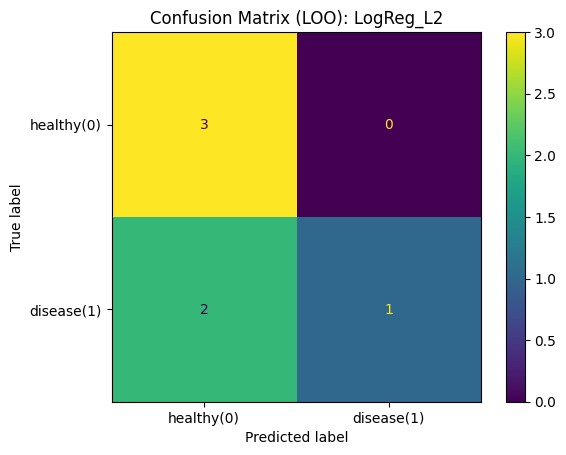

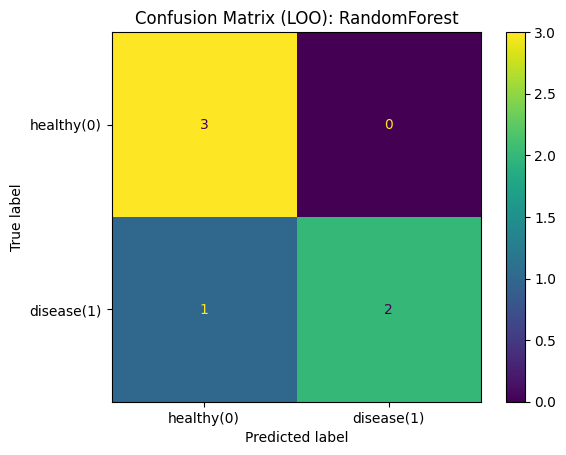

In [ ]:
# Visualize the confusion matrix for each classifier.
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
)

for name in models:
    cm = confusion_matrix(
        truth,
        preds[name],
        labels=[0, 1],
    )

    cm_display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Healthy", "ER+ tumor"],
    )

    cm_display.plot(values_format="d")
    plt.title(
        f"Leave-One-Sample-Out Confusion Matrix — {name}"
    )
    plt.tight_layout()
    plt.show()

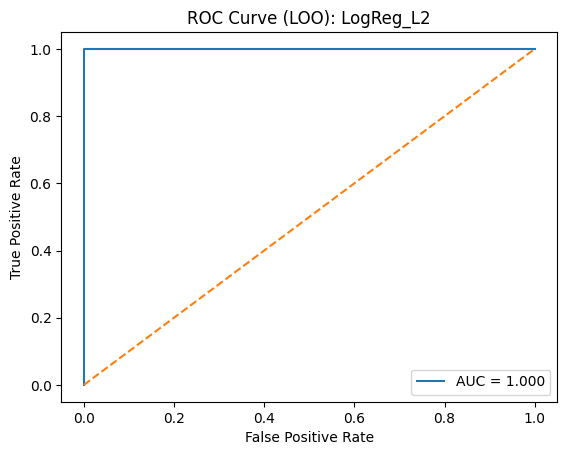

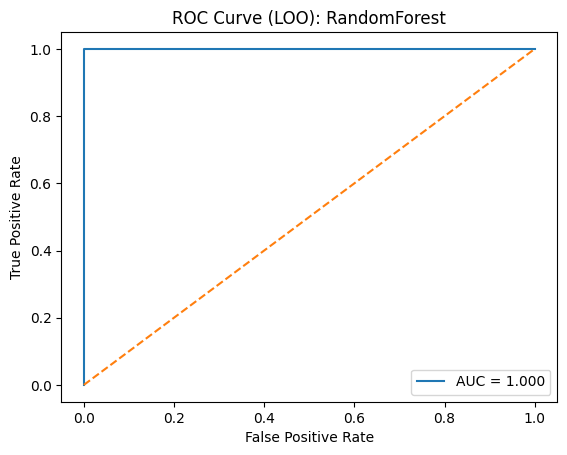

In [ ]:
# Plot ROC curves using held-out disease probabilities.
from sklearn.metrics import roc_curve, roc_auc_score

for name in models:
    y_score = np.asarray(probs[name])

    fpr, tpr, _ = roc_curve(
        truth,
        y_score,
        pos_label=1,
    )
    roc_auc = roc_auc_score(truth, y_score)

    plt.figure()
    plt.plot(
        fpr,
        tpr,
        label=f"ROC-AUC = {roc_auc:.3f}",
    )
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Chance reference",
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"Leave-One-Sample-Out ROC Curve — {name}")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

In [ ]:
# Calculate complementary classification performance metrics.
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
)

rows = []

for name in models:
    y_pred = np.asarray(preds[name])
    y_prob = np.asarray(probs[name])

    accuracy = accuracy_score(truth, y_pred)

    precision, recall, f1, _ = precision_recall_fscore_support(
        truth,
        y_pred,
        average="binary",
        zero_division=0,
    )

    roc_auc = roc_auc_score(truth, y_prob)

    rows.append({
        "model": name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
    })

metrics_df = pd.DataFrame(rows)

display(
    metrics_df.style.format({
        "accuracy": "{:.3f}",
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1": "{:.3f}",
        "roc_auc": "{:.3f}",
    })
)

,model,accuracy,precision,recall,f1,roc_auc
0,LogReg_L2,0.666667,1.0,0.333333,0.5,1.0
1,RandomForest,0.833333,1.0,0.666667,0.8,1.0


In [ ]:
# Export the classifier performance comparison.
metrics_path = PROJECT_DIR / "step8_model_metrics.csv"

metrics_df.to_csv(metrics_path, index=False)

print(f"Saved model metrics: {metrics_path}")

Saved: /content/drive/MyDrive/bioinformatics final project/step8_model_metrics.csv


In [ ]:
# Record held-out predictions and disease probabilities for each sample.
pred_df = pd.DataFrame({
    "sample_id": sample_ids,
    "y_true": truth,
    "logreg_pred": preds["LogReg_L2"],
    "logreg_prob": probs["LogReg_L2"],
    "rf_pred": preds["RandomForest"],
    "rf_prob": probs["RandomForest"],
})

prediction_path = PROJECT_DIR / "step8_per_sample_predictions.csv"
pred_df.to_csv(prediction_path, index=False)

print(f"Saved per-sample predictions: {prediction_path}")
display(pred_df)

Saved: /content/drive/MyDrive/bioinformatics final project/step8_per_sample_predictions.csv


,sample_id,y_true,logreg_pred,logreg_prob,rf_pred,rf_prob
0,GSM4909253_N-PM0092-Total,0,0,0.009008,0,0.372
1,GSM4909254_N-PM0019-Total,0,0,0.005096,0,0.360
2,GSM4909265_N-PM0233-Total,0,0,0.030233,0,0.350
3,GSM4909296_ER-MH0001,1,1,0.844758,1,0.502
4,GSM4909297_ER-MH0125,1,0,0.163536,0,0.492
5,GSM4909298_ER-PM0360,1,0,0.491913,1,0.510


### Logistic Regression Feature Interpretation

The fitted logistic regression coefficients provide a descriptive ranking of cell-type-specific expression features. Positive coefficients indicate an association with the tumor class, while negative coefficients indicate an association with the healthy class. These rankings help connect the classifier to the underlying expression signatures.

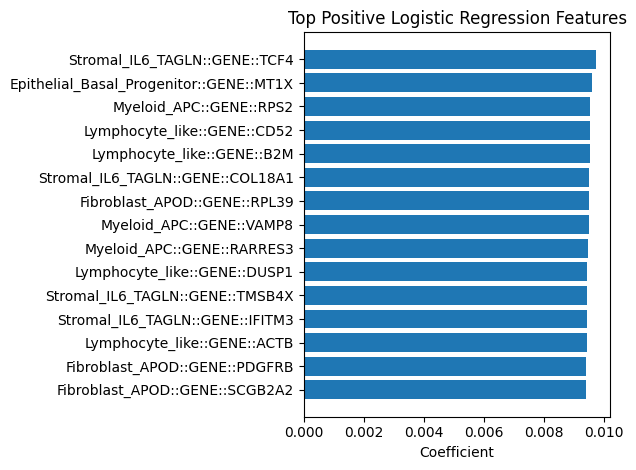

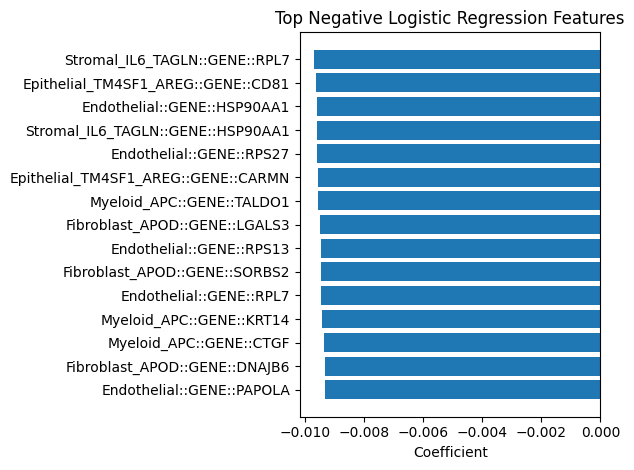

In [ ]:
# Visualize the strongest positive and negative logistic regression features.
coefficient_path = PROJECT_DIR / "step7_logreg_feature_coefficients.csv"
coef_df = pd.read_csv(coefficient_path)

top_pos = coef_df.nlargest(15, "coef").copy()
top_neg = coef_df.nsmallest(15, "coef").copy()


def format_feature_label(feature):
    """Convert a feature name into a readable cell-type/gene label."""
    if "::GENE::" in feature:
        cell_type, gene = feature.split("::GENE::", 1)
        return f"{gene} | {cell_type}"
    return feature


for subset, title in [
    (top_pos, "Features Associated with the Tumor Class"),
    (top_neg, "Features Associated with the Healthy Class"),
]:
    plot_data = subset.sort_values("coef").copy()
    labels = [
        format_feature_label(feature)
        for feature in plot_data["feature"]
    ]

    plt.figure(figsize=(9, 6))
    plt.barh(labels, plot_data["coef"])
    plt.xlabel("Logistic Regression Coefficient")
    plt.title(title)
    plt.tight_layout()
    plt.show()

In [ ]:
# Summarize the leading classifier and the main evaluation metrics.
best = metrics_df.sort_values(
    ["roc_auc", "f1", "accuracy"],
    ascending=False,
).iloc[0]

rf_recall = metrics_df.loc[
    metrics_df["model"] == "RandomForest", "recall"
].iloc[0]

logreg_recall = metrics_df.loc[
    metrics_df["model"] == "LogReg_L2", "recall"
].iloc[0]

summary = (
    f"Under leave-one-sample-out cross-validation across "
    f"{len(truth)} biological samples, {best['model']} ranked highest "
    f"using ROC-AUC, F1, and accuracy as the comparison criteria. "
    f"Its accuracy was {best['accuracy']:.3f}, F1 score was "
    f"{best['f1']:.3f}, and ROC-AUC was {best['roc_auc']:.3f}. "
    f"Random Forest recall was {rf_recall:.3f}, compared with "
    f"{logreg_recall:.3f} for logistic regression."
)

print(summary)

<a id="step-9"></a>
## Step 9 — Model Comparison and Feature Interpretation

Model performance and sample-level prediction errors are examined alongside feature-level results. Logistic regression coefficients are ranked and linked to differential-expression statistics, connecting predictive signals to their corresponding genes and cell-type contexts.

In [ ]:
# Load the feature matrix, model results, predictions, and DEG statistics.
import pandas as pd
import numpy as np
from pathlib import Path

df_feat = pd.read_csv(
    PROJECT_DIR / "step7_pseudobulk_feature_matrix.csv"
)
coef_df = pd.read_csv(
    PROJECT_DIR / "step7_logreg_feature_coefficients.csv"
)
deg_all = pd.read_csv(
    PROJECT_DIR / "step6_DEGs_by_celltype_disease_vs_healthy.csv"
)
metrics_df = pd.read_csv(
    PROJECT_DIR / "step8_model_metrics.csv"
)
pred_df = pd.read_csv(
    PROJECT_DIR / "step8_per_sample_predictions.csv"
)

# Verify the dimensions of the saved analysis artifacts.
print("Feature matrix:", df_feat.shape)
print("Coefficient table:", coef_df.shape)
print("Differential-expression table:", deg_all.shape)
print("Model metrics:", metrics_df.shape)
print("Per-sample predictions:", pred_df.shape)

((6, 1954), (1952, 2), (193328, 8), (2, 6), (6, 6))

In [ ]:
# Rank classifiers by ROC-AUC, followed by F1 score and accuracy.
best = (
    metrics_df
    .sort_values(
        ["roc_auc", "f1", "accuracy"],
        ascending=False,
    )
    .iloc[0]
)

best_model = best["model"]

print("Selected model:", best_model)
display(best.to_frame(name="value"))

('RandomForest',
 {'model': 'RandomForest',
  'accuracy': 0.8333333333333334,
  'precision': 1.0,
  'recall': 0.6666666666666666,
  'f1': 0.8,
  'roc_auc': 1.0})

### Sample-Level Prediction Analysis

Held-out predictions are compared with the known sample labels to identify correctly classified samples, false positives, and false negatives. This provides a direct view of the classification outcomes underlying the aggregate performance metrics.

In [ ]:
# Select the prediction and probability columns for the chosen model.
model_columns = {
    "LogReg_L2": ("logreg_pred", "logreg_prob"),
    "RandomForest": ("rf_pred", "rf_prob"),
}

if best_model not in model_columns:
    raise ValueError(f"Unexpected model name: {best_model}")

pred_col, prob_col = model_columns[best_model]

# Compare predicted and observed sample labels.
pred_df["is_correct"] = (
    pred_df[pred_col] == pred_df["y_true"]
)

pred_df["true_condition"] = pred_df["y_true"].map({
    0: "Healthy",
    1: "ER+ tumor",
})

pred_df["predicted_condition"] = pred_df[pred_col].map({
    0: "Healthy",
    1: "ER+ tumor",
})

pred_df["error_type"] = np.select(
    [
        pred_df["is_correct"],
        (pred_df["y_true"] == 1) & (pred_df[pred_col] == 0),
        (pred_df["y_true"] == 0) & (pred_df[pred_col] == 1),
    ],
    [
        "correct",
        "false_negative",
        "false_positive",
    ],
    default="unknown",
)

# Display correct predictions and errors together.
display(
    pred_df.sort_values(
        ["error_type", "sample_id"]
    )
)

,sample_id,y_true,logreg_pred,logreg_prob,rf_pred,rf_prob,is_correct,error_type
0,GSM4909253_N-PM0092-Total,0,0,0.009008,0,0.372,True,correct
1,GSM4909254_N-PM0019-Total,0,0,0.005096,0,0.360,True,correct
2,GSM4909265_N-PM0233-Total,0,0,0.030233,0,0.350,True,correct
3,GSM4909296_ER-MH0001,1,1,0.844758,1,0.502,True,correct
5,GSM4909298_ER-PM0360,1,0,0.491913,1,0.510,True,correct
4,GSM4909297_ER-MH0125,1,0,0.163536,0,0.492,False,false_negative


In [ ]:
# Summarize the selected model's performance and confusion matrix.
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    pred_df["y_true"].astype(int),
    pred_df[pred_col].astype(int),
    labels=[0, 1],
)

tn, fp, fn, tp = cm.ravel()

interpretation = [
    f"Selected model: {best_model}.",
    (
        f"Accuracy: {best['accuracy']:.3f}; "
        f"precision: {best['precision']:.3f}; "
        f"recall: {best['recall']:.3f}; "
        f"F1 score: {best['f1']:.3f}; "
        f"ROC-AUC: {best['roc_auc']:.3f}."
    ),
    (
        f"Confusion matrix (TN, FP, FN, TP): "
        f"({tn}, {fp}, {fn}, {tp})."
    ),
    (
        "The sample-level results provide an exploratory comparison "
        "of classifier performance across the six biological samples."
    ),
]

print("\n".join(interpretation))

Best model by ROC-AUC/F1 was RandomForest.
LOO metrics: accuracy=0.833, precision=1.000, recall=0.667, F1=0.800, ROC-AUC=1.000.
Confusion matrix (TN, FP, FN, TP) = (3, 0, 1, 2).
ROC-AUC can be inflated with only 6 samples (3 vs 3); we interpret it cautiously and focus on error types and biological plausibility of features.


### Ranking Predictive Expression Features

Logistic regression coefficients are ranked to identify the cell-type-specific expression features most strongly associated with each predicted class. Positive coefficients correspond to the tumor class, while negative coefficients correspond to the healthy class. These rankings provide a starting point for examining the biological context of the classifier.

In [ ]:
# Rank features by their fitted logistic regression coefficients.
top_k = 25

top_pos = (
    coef_df
    .nlargest(top_k, "coef")
    .copy()
)

top_neg = (
    coef_df
    .nsmallest(top_k, "coef")
    .copy()
)

print("Features with the strongest positive coefficients:")
display(top_pos)

print("Features with the strongest negative coefficients:")
display(top_neg)

(                                    feature      coef
 0             Stromal_IL6_TAGLN::GENE::TCF4  0.009724
 1   Epithelial_Basal_Progenitor::GENE::MT1X  0.009605
 2                   Myeloid_APC::GENE::RPS2  0.009543
 3               Lymphocyte_like::GENE::CD52  0.009530
 4                Lymphocyte_like::GENE::B2M  0.009528
 5          Stromal_IL6_TAGLN::GENE::COL18A1  0.009500
 6              Fibroblast_APOD::GENE::RPL39  0.009486
 7                  Myeloid_APC::GENE::VAMP8  0.009481
 8                Myeloid_APC::GENE::RARRES3  0.009457
 9              Lymphocyte_like::GENE::DUSP1  0.009445
 10          Stromal_IL6_TAGLN::GENE::TMSB4X  0.009429
 11          Stromal_IL6_TAGLN::GENE::IFITM3  0.009429
 12              Lymphocyte_like::GENE::ACTB  0.009425
 13            Fibroblast_APOD::GENE::PDGFRB  0.009401
 14           Fibroblast_APOD::GENE::SCGB2A2  0.009393
 15                  Myeloid_APC::GENE::AIF1  0.009392
 16                Myeloid_APC::GENE::S100A4  0.009387
 17       

In [ ]:
# Separate each feature into its cell-type and gene components.
for feature_table in (top_pos, top_neg):
    feature_table[["cell_type", "gene"]] = (
        feature_table["feature"]
        .str.split("::GENE::", n=1, expand=True)
    )

# Retain the relevant differential-expression statistics.
deg_lookup = (
    deg_all
    .rename(columns={"names": "gene"})
    [["cell_type", "gene", "logfoldchanges", "pvals_adj", "scores"]]
    .copy()
)

# Add biological context to the ranked feature tables.
top_pos_ctx = top_pos.merge(
    deg_lookup,
    on=["cell_type", "gene"],
    how="left",
)

top_neg_ctx = top_neg.merge(
    deg_lookup,
    on=["cell_type", "gene"],
    how="left",
)

print("Positive-coefficient features with DEG context:")
display(top_pos_ctx.head(15))

print("Negative-coefficient features with DEG context:")
display(top_neg_ctx.head(15))

(                                    feature      coef  \
 0             Stromal_IL6_TAGLN::GENE::TCF4  0.009724   
 1   Epithelial_Basal_Progenitor::GENE::MT1X  0.009605   
 2                   Myeloid_APC::GENE::RPS2  0.009543   
 3               Lymphocyte_like::GENE::CD52  0.009530   
 4                Lymphocyte_like::GENE::B2M  0.009528   
 5          Stromal_IL6_TAGLN::GENE::COL18A1  0.009500   
 6              Fibroblast_APOD::GENE::RPL39  0.009486   
 7                  Myeloid_APC::GENE::VAMP8  0.009481   
 8                Myeloid_APC::GENE::RARRES3  0.009457   
 9              Lymphocyte_like::GENE::DUSP1  0.009445   
 10          Stromal_IL6_TAGLN::GENE::TMSB4X  0.009429   
 11          Stromal_IL6_TAGLN::GENE::IFITM3  0.009429   
 12              Lymphocyte_like::GENE::ACTB  0.009425   
 13            Fibroblast_APOD::GENE::PDGFRB  0.009401   
 14           Fibroblast_APOD::GENE::SCGB2A2  0.009393   
 
                       cell_type     gene  logfoldchanges      pvals_a

In [ ]:
# Export feature rankings and per-sample error analysis.
pos_path = (
    PROJECT_DIR
    / "step9_top_positive_features_with_deg_context.csv"
)
neg_path = (
    PROJECT_DIR
    / "step9_top_negative_features_with_deg_context.csv"
)
err_path = (
    PROJECT_DIR
    / "step9_per_sample_errors_best_model.csv"
)

top_pos_ctx.to_csv(pos_path, index=False)
top_neg_ctx.to_csv(neg_path, index=False)

pred_df.sort_values(
    ["error_type", "sample_id"]
).to_csv(err_path, index=False)

print(f"Saved: {pos_path}")
print(f"Saved: {neg_path}")
print(f"Saved: {err_path}")

Saved: /content/drive/MyDrive/bioinformatics final project/step9_top_positive_features_with_deg_context.csv
Saved: /content/drive/MyDrive/bioinformatics final project/step9_top_negative_features_with_deg_context.csv
Saved: /content/drive/MyDrive/bioinformatics final project/step9_per_sample_errors_best_model.csv


### Integrated Interpretation

The final summary combines model performance, sample-level errors, and the ranked expression features. The coefficient-associated genes are considered alongside their cell-type-specific differential-expression results to identify candidate signals for further biological investigation.

In [ ]:
# Generate a concise summary of the classification and feature results.
best_errs = pred_df.loc[
    pred_df["error_type"] != "correct",
    [
        "sample_id",
        "true_condition",
        "predicted_condition",
        prob_col,
        "error_type",
    ],
].copy()

recall_by_model = metrics_df.set_index("model")["recall"]

logreg_recall = recall_by_model.get("LogReg_L2", np.nan)
rf_recall = recall_by_model.get("RandomForest", np.nan)

narr = [
    (
        f"{best_model} ranked highest under the selected comparison "
        f"criteria, with accuracy {best['accuracy']:.3f}, "
        f"F1 score {best['f1']:.3f}, and ROC-AUC "
        f"{best['roc_auc']:.3f}."
    ),
    (
        f"Recall was {rf_recall:.3f} for Random Forest and "
        f"{logreg_recall:.3f} for logistic regression."
    ),
    (
        "The model's predictions were examined at the biological-sample "
        "level, while logistic regression coefficients were linked to "
        "cell-type-specific differential-expression results."
    ),
]

if best_errs.empty:
    narr.append(
        "No misclassifications were recorded for the selected model."
    )
else:
    narr.append("Misclassified samples:")
    narr.append(best_errs.to_string(index=False))

narr.append(
    "The ranked expression features provide candidate signals for "
    "biological interpretation; their predictive associations do not "
    "by themselves establish causal mechanisms."
)

print("\n\n".join(narr))

<a id="step-10"></a>
## Step 10 — Results Synthesis

The final stage consolidates classification metrics, confusion-matrix counts, prediction errors, and ranked features into report-ready outputs. Together, these analyses provide an exploratory view of cellular heterogeneity in healthy mammary tissue and ER-positive breast tumors, and of the potential value of cell-type-specific expression signatures for distinguishing the two conditions.

In [ ]:
# Load the saved model evaluation and feature interpretation results.
import pandas as pd
import numpy as np
from pathlib import Path


metrics_df = pd.read_csv(
    PROJECT_DIR / "step8_model_metrics.csv"
)

pred_df = pd.read_csv(
    PROJECT_DIR / "step9_per_sample_errors_best_model.csv"
)

top_pos = pd.read_csv(
    PROJECT_DIR / "step9_top_positive_features_with_deg_context.csv"
)

top_neg = pd.read_csv(
    PROJECT_DIR / "step9_top_negative_features_with_deg_context.csv"
)

print("Model metrics:", metrics_df.shape)
print("Sample-level predictions:", pred_df.shape)
print("Positive-coefficient features:", top_pos.shape)
print("Negative-coefficient features:", top_neg.shape)

(          model  accuracy  precision    recall   f1  roc_auc
 0     LogReg_L2  0.666667        1.0  0.333333  0.5      1.0
 1  RandomForest  0.833333        1.0  0.666667  0.8      1.0,
                    sample_id  y_true  logreg_pred  logreg_prob  rf_pred  \
 0  GSM4909253_N-PM0092-Total       0            0     0.009008        0   
 1  GSM4909254_N-PM0019-Total       0            0     0.005096        0   
 2  GSM4909265_N-PM0233-Total       0            0     0.030233        0   
 3       GSM4909296_ER-MH0001       1            1     0.844758        1   
 4       GSM4909298_ER-PM0360       1            0     0.491913        1   
 
    rf_prob  is_correct error_type  
 0    0.372        True    correct  
 1    0.360        True    correct  
 2    0.350        True    correct  
 3    0.502        True    correct  
 4    0.510        True    correct  ,
                                    feature      coef  \
 0            Stromal_IL6_TAGLN::GENE::TCF4  0.009724   
 1  Epithelial_Bas

In [ ]:
# Select the leading classifier using the established ranking criteria.
best_row = (
    metrics_df
    .sort_values(
        ["roc_auc", "f1", "accuracy"],
        ascending=False,
    )
    .iloc[0]
)

best_model = best_row["model"]

prediction_columns = {
    "LogReg_L2": ("logreg_pred", "logreg_prob"),
    "RandomForest": ("rf_pred", "rf_prob"),
}

pred_col, prob_col = prediction_columns[best_model]

# Calculate the confusion matrix using a consistent class order.
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    pred_df["y_true"].astype(int),
    pred_df[pred_col].astype(int),
    labels=[0, 1],
)

tn, fp, fn, tp = cm.ravel()

print("Selected model:", best_model)
print("Class order: healthy (0), ER+ tumor (1)")
print("Confusion matrix:")
print(cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

(3, 0, 1, 2)

In [ ]:
# Identify samples misclassified by the selected model.
error_columns = [
    "sample_id",
    "y_true",
    pred_col,
    prob_col,
    "error_type",
]

errors = pred_df.loc[
    pred_df["error_type"] != "correct",
    error_columns,
].copy()

# Add readable condition labels for interpretation.
errors["true_condition"] = errors["y_true"].map({
    0: "Healthy",
    1: "ER+ tumor",
})

errors["predicted_condition"] = errors[pred_col].map({
    0: "Healthy",
    1: "ER+ tumor",
})

display(errors)

,sample_id,y_true,rf_pred,rf_prob,error_type
5,GSM4909297_ER-MH0125,1,0,0.492,false_negative


### Summary of Classification Performance

The final results table consolidates the selected model's evaluation metrics, confusion-matrix counts, and sample distribution. It provides a compact reference for the quantitative findings reported in the conclusion.

In [ ]:
# Consolidate model performance and sample-level outcomes.
sample_labels = (
    pred_df[["sample_id", "y_true"]]
    .drop_duplicates("sample_id")
)

final_summary = pd.DataFrame([{
    "best_model": best_model,
    "accuracy": best_row["accuracy"],
    "precision": best_row["precision"],
    "recall": best_row["recall"],
    "f1": best_row["f1"],
    "roc_auc": best_row["roc_auc"],
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp,
    "n_samples": sample_labels["sample_id"].nunique(),
    "n_healthy": int((sample_labels["y_true"] == 0).sum()),
    "n_disease": int((sample_labels["y_true"] == 1).sum()),
}])

display(
    final_summary.style.format({
        "accuracy": "{:.3f}",
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1": "{:.3f}",
        "roc_auc": "{:.3f}",
    })
)

,best_model,accuracy,precision,recall,f1,roc_auc,TN,FP,FN,TP,n_samples,n_healthy,n_disease
0,RandomForest,0.833333,1.0,0.666667,0.8,1.0,3,0,1,2,6,3,3


In [ ]:
# Prepare concise summaries of the strongest logistic regression features.
def top_feature_bullets(feature_table, n=10):
    """Format ranked features with their cell-type context."""
    columns = [
        column
        for column in [
            "feature",
            "cell_type",
            "gene",
            "logfoldchanges",
            "pvals_adj",
        ]
        if column in feature_table.columns
    ]

    result = feature_table[columns].head(n).copy()

    result["bullet"] = result.apply(
        lambda row: (
            f"- {row.get('cell_type', 'Unknown')} / "
            f"{row.get('gene', 'Unknown')}"
        ),
        axis=1,
    )

    return result


pos_bullets = top_feature_bullets(top_pos)
neg_bullets = top_feature_bullets(top_neg)

print("Features associated with the tumor class:")
print("\n".join(pos_bullets["bullet"]))

print("\nFeatures associated with the healthy class:")
print("\n".join(neg_bullets["bullet"]))

Top positive features:
- Stromal_IL6_TAGLN / TCF4 (Stromal_IL6_TAGLN::GENE::TCF4)
- Epithelial_Basal_Progenitor / MT1X (Epithelial_Basal_Progenitor::GENE::MT1X)
- Myeloid_APC / RPS2 (Myeloid_APC::GENE::RPS2)
- Lymphocyte_like / CD52 (Lymphocyte_like::GENE::CD52)
- Lymphocyte_like / B2M (Lymphocyte_like::GENE::B2M)
- Stromal_IL6_TAGLN / COL18A1 (Stromal_IL6_TAGLN::GENE::COL18A1)
- Fibroblast_APOD / RPL39 (Fibroblast_APOD::GENE::RPL39)
- Myeloid_APC / VAMP8 (Myeloid_APC::GENE::VAMP8)
- Myeloid_APC / RARRES3 (Myeloid_APC::GENE::RARRES3)
- Lymphocyte_like / DUSP1 (Lymphocyte_like::GENE::DUSP1)

Top negative features:
- Stromal_IL6_TAGLN / RPL7 (Stromal_IL6_TAGLN::GENE::RPL7)
- Epithelial_TM4SF1_AREG / CD81 (Epithelial_TM4SF1_AREG::GENE::CD81)
- Endothelial / HSP90AA1 (Endothelial::GENE::HSP90AA1)
- Stromal_IL6_TAGLN / HSP90AA1 (Stromal_IL6_TAGLN::GENE::HSP90AA1)
- Endothelial / RPS27 (Endothelial::GENE::RPS27)
- Epithelial_TM4SF1_AREG / CARMN (Epithelial_TM4SF1_AREG::GENE::CARMN)
- Myeloid

### Discussion and Conclusion

The classification results are interpreted alongside the cell-type-specific expression features. This integrated view highlights how single-cell analysis can characterize tissue heterogeneity and generate interpretable candidate signatures for distinguishing healthy mammary tissue from ER-positive breast tumors.

In [ ]:
# Generate a concise, results-based discussion and conclusion.
if errors.empty:
    error_text = "No misclassified samples were recorded."
else:
    error_lines = []

    for _, row in errors.iterrows():
        error_lines.append(
            f"- {row['sample_id']}: "
            f"{row['true_condition']} predicted as "
            f"{row['predicted_condition']} "
            f"(predicted tumor probability: {row[prob_col]:.3f})."
        )

    error_text = "\n".join(error_lines)

# Summarize the main cell-type contexts represented among the leading features.
feature_cell_types = (
    pd.concat([
        top_pos.head(10)[["cell_type"]],
        top_neg.head(10)[["cell_type"]],
    ])
    ["cell_type"]
    .value_counts()
    .head(5)
    .index
    .tolist()
)

discussion = f"""
## Discussion and Conclusion

### Classification Performance

Two supervised classifiers were compared using leave-one-sample-out
cross-validation across six biological samples: three healthy mammary
tissue samples and three ER-positive breast tumor samples.

{best_model} ranked highest under the selected comparison criteria,
with accuracy of {best_row['accuracy']:.3f}, precision of
{best_row['precision']:.3f}, recall of {best_row['recall']:.3f},
F1 score of {best_row['f1']:.3f}, and ROC-AUC of
{best_row['roc_auc']:.3f}.

The confusion matrix (TN, FP, FN, TP) was
({tn}, {fp}, {fn}, {tp}).

### Sample-Level Predictions

{error_text}

### Biological Interpretation

The ranked logistic regression features span cell-type-specific
expression signatures. Among the leading features, represented
cell populations include: {", ".join(feature_cell_types)}.

Linking these features to differential-expression statistics connects
the classification analysis to the cellular heterogeneity characterized
in the preceding single-cell workflow.

### Conclusion

This project integrates single-cell quality control, preprocessing,
batch-aware clustering, marker-based cell-type annotation,
cell-type-specific differential expression, and sample-level
classification. It demonstrates an end-to-end analytical workflow
that connects cellular characterization with interpretable gene-
expression features.

The classification findings are exploratory given the six-sample
dataset and the use of DEG-based feature selection before
cross-validation. Independent validation and feature selection
within each training fold would be appropriate next steps for
assessing generalizability.
"""

print(discussion)

In [ ]:
# Export the final summary table and discussion text.
summary_path = PROJECT_DIR / "step10_final_summary.csv"
text_path = PROJECT_DIR / "step10_discussion_conclusion.txt"

final_summary.to_csv(summary_path, index=False)
text_path.write_text(discussion, encoding="utf-8")

print(f"Saved summary: {summary_path}")
print(f"Saved discussion: {text_path}")

Saved: /content/drive/MyDrive/bioinformatics final project/step10_final_summary.csv
Saved: /content/drive/MyDrive/bioinformatics final project/step10_discussion_conclusion.txt
